In [27]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [ ]:
%pip install earthengine-api

# 1 Initialise Earth Engine and define observation sites
## 1.1 Authenticate Google Earth Engine

In [1]:
import ee

ee.Authenticate(auth_mode='localhost')

ee.Initialize(project='phdchap02')

print("Google Earth Engine successfully connected!")


Successfully saved authorization token.
Google Earth Engine successfully connected!


## 1.2 Define the eight observation sites

In [3]:
# =====================================================
# STEP 1: DEFINE OBSERVATION SITES
# =====================================================

site_data = [
    ['Limmen', 'NT', '1A', 135.78877, -15.14622],
    ['Limmen', 'NT', '1B', 135.83699, -15.17115],
    ['Mule', 'NT', '2A', 136.43415, -15.64737],
    ['Mule', 'NT', '2B', 136.44197, -15.65092],
    ['Karumba', 'QLD', '3A', 140.85358, -17.42256],
    ['Karumba', 'QLD', '3B', 140.89625, -17.34002],
    ['Mitchell', 'QLD', '4A', 141.66542, -15.02732],
    ['Mitchell', 'QLD', '4B', 141.66092, -14.99654]
]

# Create Earth Engine features
features = []

for location, state, code, lon, lat in site_data:

    # Geographic coordinates
    point = ee.Geometry.Point([lon, lat])

    # Project to Australian Albers
    projected = point.transform('EPSG:3577', 1)

    coordinates = projected.coordinates()

    x = ee.Number(coordinates.get(0))
    y = ee.Number(coordinates.get(1))

    # Create 90 x 90 m square
    geometry = ee.Geometry.Rectangle(
        [
            x.subtract(45),
            y.subtract(45),
            x.add(45),
            y.add(45)
        ],
        proj='EPSG:3577',
        geodesic=False
    )

    feature = ee.Feature(geometry, {
        'Location': location,
        'State': state,
        'Site_Code': code,
        'Longitude': lon,
        'Latitude': lat
    })

    features.append(feature)

# Combine features into FeatureCollection
sites = ee.FeatureCollection(features)

print("Number of observation sites:", sites.size().getInfo())

Number of observation sites: 8


## 1.3 Check the site information

In [6]:
site_info = sites.getInfo()

site_table = pd.DataFrame([
    feature['properties']
    for feature in site_info['features']
])

display(site_table)

,Latitude,Location,Longitude,Site_Code,State
0,-15.14622,Limmen,135.78877,1A,NT
1,-15.17115,Limmen,135.83699,1B,NT
2,-15.64737,Mule,136.43415,2A,NT
3,-15.65092,Mule,136.44197,2B,NT
4,-17.42256,Karumba,140.85358,3A,QLD
5,-17.34002,Karumba,140.89625,3B,QLD
6,-15.02732,Mitchell,141.66542,4A,QLD
7,-14.99654,Mitchell,141.66092,4B,QLD


## 1.4 Create output folder

In [9]:
output_dir = Path("mangrove_outputs")
output_dir.mkdir(exist_ok=True)

print("Output folder:", output_dir.resolve())

Output folder: C:\Users\percy\Documents\studies\visual_studio_code\EOS\notebook\mangrove_outputs


# 2 Retrieve landsat imagery
## 2.1 Define the study periods

In [10]:
# Years and seasonal period
years = [2014, 2016, 2025]

start_month = 6
end_month = 11  # Exclusive: includes all of October

print("Study years:", years)
print("Study period: June to October")

Study years: [2014, 2016, 2025]
Study period: June to October


## 2.2 Access the Landsat 8 image collection

In [11]:
# Landsat 8 Collection 2 Level 2
landsat_collection = ee.ImageCollection(
    "LANDSAT/LC08/C02/T1_L2"
)

# Filter imagery covering the eight observation sites
landsat_collection = (
    landsat_collection
    .filterBounds(sites.geometry())
)

print("Landsat collection successfully accessed.")

Landsat collection successfully accessed.


## 2.3 Check the number of available images for each year

In [12]:
# Check image availability for each study year
image_counts = []

for year in years:

    start_date = ee.Date.fromYMD(year, start_month, 1)
    end_date = ee.Date.fromYMD(year, end_month, 1)

    yearly_collection = (
        landsat_collection
        .filterDate(start_date, end_date)
    )

    image_count = yearly_collection.size().getInfo()

    image_counts.append({
        "Year": year,
        "Start_Date": f"{year}-06-01",
        "End_Date": f"{year}-10-31",
        "Number_of_Images": image_count
    })

    print(f"{year}: {image_count} images")

# Display results
image_count_table = pd.DataFrame(image_counts)
display(image_count_table)

2014: 57 images
2016: 59 images
2025: 56 images


,Year,Start_Date,End_Date,Number_of_Images
0,2014,2014-06-01,2014-10-31,57
1,2016,2016-06-01,2016-10-31,59
2,2025,2025-06-01,2025-10-31,56


## 2.4 Check the image availability around each observation site

In [13]:
site_image_counts = []

for location, state, code, lon, lat in site_data:

    point = ee.Geometry.Point([lon, lat])

    site_results = []

    for year in years:

        start_date = ee.Date.fromYMD(year, start_month, 1)
        end_date = ee.Date.fromYMD(year, end_month, 1)

        collection = (
            landsat_collection
            .filterBounds(point)
            .filterDate(start_date, end_date)
        )

        count = collection.size().getInfo()
        site_results.append(count)

    site_image_counts.append({
        "Location": location,
        "State": state,
        "Site_Code": code,
        "Images_2014": site_results[0],
        "Images_2016": site_results[1],
        "Images_2025": site_results[2]
    })

site_image_table = pd.DataFrame(site_image_counts)

display(site_image_table)

,Location,State,Site_Code,Images_2014,Images_2016,Images_2025
0,Limmen,NT,1A,18,20,18
1,Limmen,NT,1B,18,20,18
2,Mule,NT,2A,9,10,9
3,Mule,NT,2B,9,10,9
4,Karumba,QLD,3A,14,7,17
5,Karumba,QLD,3B,19,16,19
6,Mitchell,QLD,4A,18,20,18
7,Mitchell,QLD,4B,20,23,19


# 3 Cloud masking and Landsat preprocessing
## 3.1 Define the preprocessing function

In [14]:
def preprocess_landsat(image):
    """
    Preprocess Landsat 8 Collection 2 Level 2 imagery.

    - Masks clouds, cloud shadows, cirrus, snow and fill pixels.
    - Masks radiometrically saturated pixels.
    - Converts optical DN values to surface reflectance.
    - Renames bands for consistency.
    """

    # QA_PIXEL cloud and quality mask
    qa = image.select("QA_PIXEL")

    mask = (
        qa.bitwiseAnd(1 << 0).eq(0)  # Fill
        .And(qa.bitwiseAnd(1 << 1).eq(0))  # Dilated cloud
        .And(qa.bitwiseAnd(1 << 2).eq(0))  # Cirrus
        .And(qa.bitwiseAnd(1 << 3).eq(0))  # Cloud
        .And(qa.bitwiseAnd(1 << 4).eq(0))  # Cloud shadow
        .And(qa.bitwiseAnd(1 << 5).eq(0))  # Snow
    )

    # Remove saturated pixels
    saturation_mask = image.select("QA_RADSAT").eq(0)

    # Select and rename optical bands
    optical_bands = (
        image.select(
            ["SR_B2", "SR_B3", "SR_B4",
             "SR_B5", "SR_B6", "SR_B7"],
            ["Blue", "Green", "Red",
             "NIR", "SWIR1", "SWIR2"]
        )
    )

    # Convert DN to surface reflectance
    optical_bands = (
        optical_bands
        .multiply(0.0000275)
        .add(-0.2)
    )

    # Apply masks and preserve image properties
    return (
        optical_bands
        .updateMask(mask)
        .updateMask(saturation_mask)
        .copyProperties(image, ["system:time_start"])
    )

## 3.2 Apply preprocessing to each year

In [15]:
# Store preprocessed collections by year
landsat_processed = {}

for year in years:

    start_date = ee.Date.fromYMD(year, 6, 1)
    end_date = ee.Date.fromYMD(year, 11, 1)

    collection = (
        landsat_collection
        .filterDate(start_date, end_date)
        .map(preprocess_landsat)
    )

    landsat_processed[year] = collection

    print(
        f"{year}:",
        collection.size().getInfo(),
        "preprocessed images"
    )

2014: 57 preprocessed images
2016: 59 preprocessed images
2025: 56 preprocessed images


## 3.3 Check the available observations after cloud masking

In [16]:
# Count valid observations at each site for each year
valid_observation_results = []

for location, state, code, lon, lat in site_data:

    # Reconstruct the 90 x 90 m site geometry
    site = sites.filter(
        ee.Filter.eq("Site_Code", code)
    ).geometry()

    row = {
        "Location": location,
        "Site_Code": code
    }

    for year in years:

        collection = landsat_processed[year]

        # Count images with valid Red-band pixels
        valid_count = collection.map(
            lambda image: image.select("Red")
            .mask()
            .rename("valid")
        ).sum()

        # Check whether the site has valid pixels
        count_at_site = valid_count.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=site,
            scale=30,
            maxPixels=1e8
        ).get("valid")

        row[f"Valid_Observations_{year}"] = (
            count_at_site.getInfo()
        )

    valid_observation_results.append(row)

valid_observation_table = pd.DataFrame(
    valid_observation_results
)

display(valid_observation_table)

,Location,Site_Code,Valid_Observations_2014,Valid_Observations_2016,Valid_Observations_2025
0,Limmen,1A,13.446897,18.462724,4.810496
1,Limmen,1B,15.706128,18.381826,13.375573
2,Mule,2A,8.187917,9.549583,9.000000
3,Mule,2B,8.142559,10.000000,9.000000
4,Karumba,3A,11.761373,5.000000,10.604632
5,Karumba,3B,17.588746,11.681423,14.460488
6,Mitchell,4A,18.000000,18.000000,4.471327
7,Mitchell,4B,17.218501,19.095019,11.683968


## 3.4 Save the observation table

In [17]:
valid_observation_table.to_csv(
    output_dir / "valid_landsat_observations.csv",
    index=False
)

print("Observation table saved.")

Observation table saved.


# 4 Calculate vegetation indices
## 4.1 Define the vegetation-index function

In [18]:
def calculate_vegetation_indices(image):

    # Select reflectance bands
    blue = image.select("Blue")
    red = image.select("Red")
    nir = image.select("NIR")
    swir1 = image.select("SWIR1")

    # NDVI
    ndvi = (
        nir.subtract(red)
        .divide(nir.add(red))
        .rename("NDVI")
    )

    # EVI
    evi = (
        nir.subtract(red)
        .multiply(2.5)
        .divide(
            nir.add(
                red.multiply(6)
            ).subtract(
                blue.multiply(7.5)
            ).add(1)
        )
        .rename("EVI")
    )

    # NDMI
    ndmi = (
        nir.subtract(swir1)
        .divide(nir.add(swir1))
        .rename("NDMI")
    )

    # Combine indices
    return (
        image.addBands([ndvi, evi, ndmi])
        .copyProperties(image, ["system:time_start"])
    )

## 4.2 Calculate indices for all three years

In [19]:
# Store collections containing vegetation indices
landsat_indices = {}

for year in years:

    collection = (
        landsat_processed[year]
        .map(calculate_vegetation_indices)
    )

    landsat_indices[year] = collection

    print(
        f"{year}:",
        collection.size().getInfo(),
        "images with vegetation indices"
    )

2014: 57 images with vegetation indices
2016: 59 images with vegetation indices
2025: 56 images with vegetation indices


## 4.3 Create seasonal median composites

In [20]:
# Create seasonal median composites
seasonal_composites = {}

for year in years:

    composite = landsat_indices[year].median()

    seasonal_composites[year] = composite

    print(f"Seasonal composite created for {year}")

Seasonal composite created for 2014
Seasonal composite created for 2016
Seasonal composite created for 2025


## 4.4 Check the vegetation-index values at the eight sites
This step extracts the mean NDVI, EVI and NDMI within each 90 × 90 m site

In [21]:
# Extract site-level vegetation indices
index_results = []

for feature in sites.getInfo()["features"]:

    properties = feature["properties"]
    site_code = properties["Site_Code"]
    location = properties["Location"]

    # Retrieve the site geometry
    site_geometry = ee.Feature(feature).geometry()

    for year in years:

        composite = seasonal_composites[year]

        # Extract mean values for the three indices
        statistics = composite.select(
            ["NDVI", "EVI", "NDMI"]
        ).reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=site_geometry,
            scale=30,
            maxPixels=1e8
        )

        values = statistics.getInfo()

        index_results.append({
            "Location": location,
            "Site_Code": site_code,
            "Year": year,
            "NDVI": values.get("NDVI"),
            "EVI": values.get("EVI"),
            "NDMI": values.get("NDMI")
        })

# Create DataFrame
index_table = pd.DataFrame(index_results)

display(index_table)

,Location,Site_Code,Year,NDVI,EVI,NDMI
0,Limmen,1A,2014,0.684706,0.470975,0.445104
1,Limmen,1A,2016,0.200283,0.108156,-0.054927
2,Limmen,1A,2025,0.261270,0.170987,0.252652
3,Limmen,1B,2014,0.632384,0.433200,0.380995
4,Limmen,1B,2016,0.221383,0.120314,-0.036176
5,Limmen,1B,2025,0.545856,0.357669,0.409947
6,Mule,2A,2014,0.543853,0.342726,0.253417
7,Mule,2A,2016,0.250749,0.140961,-0.013536
8,Mule,2A,2025,0.550220,0.319935,0.400491
9,Mule,2B,2014,0.437322,0.277251,0.219356


## 4.5 Save the results

In [22]:
index_table.to_csv(
    output_dir / "mangrove_vegetation_indices.csv",
    index=False
)

print("Vegetation indices saved successfully.")

Vegetation indices saved successfully.


# 5 Quantify vegetation changes between the study years.
## 5.1 Calculate changes in NDVI, EVI and NDMI

In [23]:
# Reshape the table to compare years
index_wide = index_table.pivot(
    index=["Location", "Site_Code"],
    columns="Year",
    values=["NDVI", "EVI", "NDMI"]
)

# Calculate changes between years
change_results = []

for (location, site_code), row in index_wide.iterrows():

    result = {
        "Location": location,
        "Site_Code": site_code
    }

    for index in ["NDVI", "EVI", "NDMI"]:

        value_2014 = row[(index, 2014)]
        value_2016 = row[(index, 2016)]
        value_2025 = row[(index, 2025)]

        result[f"{index}_2014"] = value_2014
        result[f"{index}_2016"] = value_2016
        result[f"{index}_2025"] = value_2025

        result[f"{index}_Change_2014_2016"] = (
            value_2016 - value_2014
        )

        result[f"{index}_Change_2014_2025"] = (
            value_2025 - value_2014
        )

        result[f"{index}_Change_2016_2025"] = (
            value_2025 - value_2016
        )

    change_results.append(result)

change_table = pd.DataFrame(change_results)

display(change_table.round(4))

,Location,Site_Code,NDVI_2014,NDVI_2016,NDVI_2025,NDVI_Change_2014_2016,NDVI_Change_2014_2025,NDVI_Change_2016_2025,EVI_2014,EVI_2016,EVI_2025,EVI_Change_2014_2016,EVI_Change_2014_2025,EVI_Change_2016_2025,NDMI_2014,NDMI_2016,NDMI_2025,NDMI_Change_2014_2016,NDMI_Change_2014_2025,NDMI_Change_2016_2025
0,Karumba,3A,0.7023,0.1571,0.6410,-0.5452,-0.0612,0.4839,0.4635,0.0773,0.3915,-0.3863,-0.0720,0.3142,0.4617,-0.0824,0.4414,-0.5441,-0.0204,0.5237
1,Karumba,3B,0.6847,0.1706,0.6724,-0.5141,-0.0123,0.5018,0.4745,0.0956,0.4734,-0.3788,-0.0011,0.3777,0.4191,-0.0813,0.4846,-0.5004,0.0656,0.5660
2,Limmen,1A,0.6847,0.2003,0.2613,-0.4844,-0.4234,0.0610,0.4710,0.1082,0.1710,-0.3628,-0.3000,0.0628,0.4451,-0.0549,0.2527,-0.5000,-0.1925,0.3076
3,Limmen,1B,0.6324,0.2214,0.5459,-0.4110,-0.0865,0.3245,0.4332,0.1203,0.3577,-0.3129,-0.0755,0.2374,0.3810,-0.0362,0.4099,-0.4172,0.0290,0.4461
4,Mitchell,4A,0.4294,0.1532,0.1405,-0.2762,-0.2889,-0.0127,0.2652,0.0820,0.0709,-0.1832,-0.1943,-0.0111,0.1786,0.0003,-0.0477,-0.1783,-0.2262,-0.0479
5,Mitchell,4B,0.6920,0.2661,0.6423,-0.4258,-0.0497,0.3761,0.4399,0.1245,0.3682,-0.3154,-0.0717,0.2437,0.3857,0.0287,0.3233,-0.3570,-0.0624,0.2946
6,Mule,2A,0.5439,0.2507,0.5502,-0.2931,0.0064,0.2995,0.3427,0.1410,0.3199,-0.2018,-0.0228,0.1790,0.2534,-0.0135,0.4005,-0.2670,0.1471,0.4140
7,Mule,2B,0.4373,0.1889,0.1999,-0.2484,-0.2374,0.0110,0.2773,0.1059,0.1222,-0.1714,-0.1550,0.0164,0.2194,-0.0285,0.2183,-0.2478,-0.0011,0.2468


## 5.2 Save the change table

In [24]:
change_table.to_csv(
    output_dir / "mangrove_vegetation_changes.csv",
    index=False
)

print("Vegetation change table saved.")

Vegetation change table saved.


## 5.3 Calculate average changes across the eight sites

In [25]:
# Calculate average changes across all eight sites
summary_columns = [
    col for col in change_table.columns
    if "Change" in col
]

mean_changes = (
    change_table[summary_columns]
    .mean()
    .to_frame(name="Mean_Change")
)

display(mean_changes.round(4))

,Mean_Change
NDVI_Change_2014_2016,-0.3998
NDVI_Change_2014_2025,-0.1441
NDVI_Change_2016_2025,0.2556
EVI_Change_2014_2016,-0.2891
EVI_Change_2014_2025,-0.1116
EVI_Change_2016_2025,0.1775
NDMI_Change_2014_2016,-0.3765
NDMI_Change_2014_2025,-0.0326
NDMI_Change_2016_2025,0.3439


# 6 Plot vegetation-index changes for each site
## 6.1 Plot NDVI, EVI and NDMI

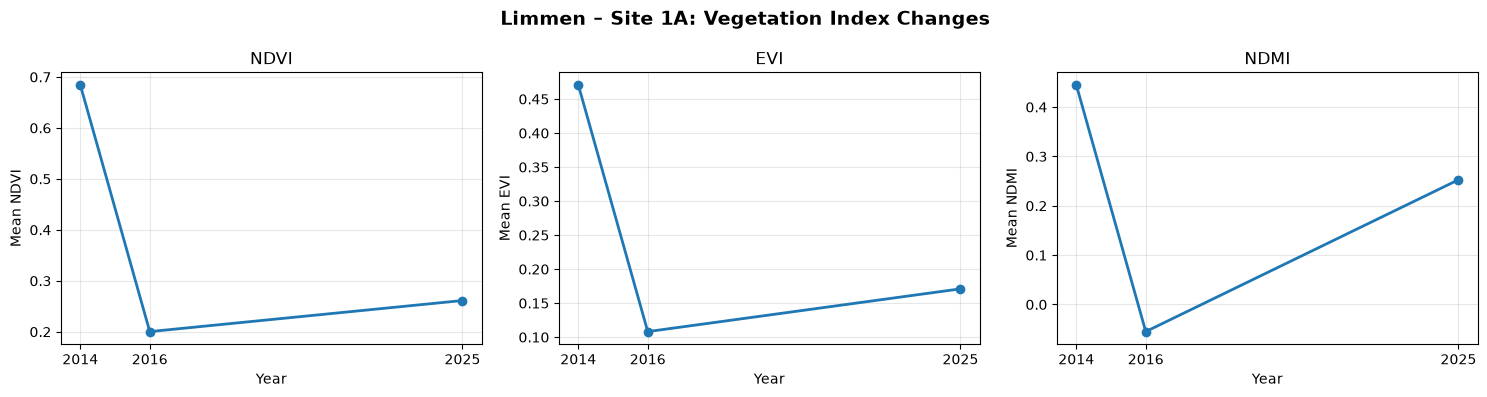

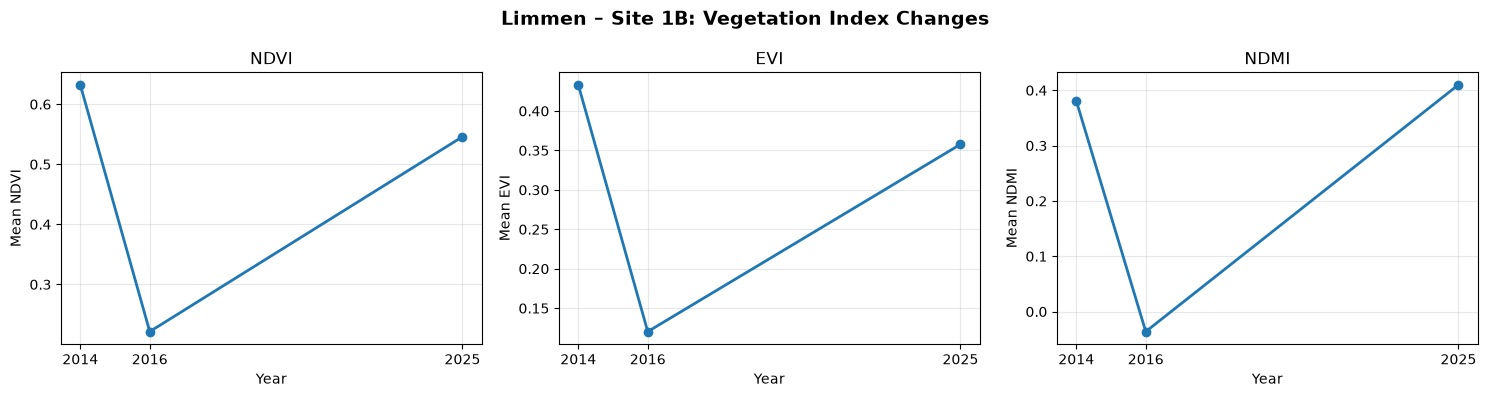

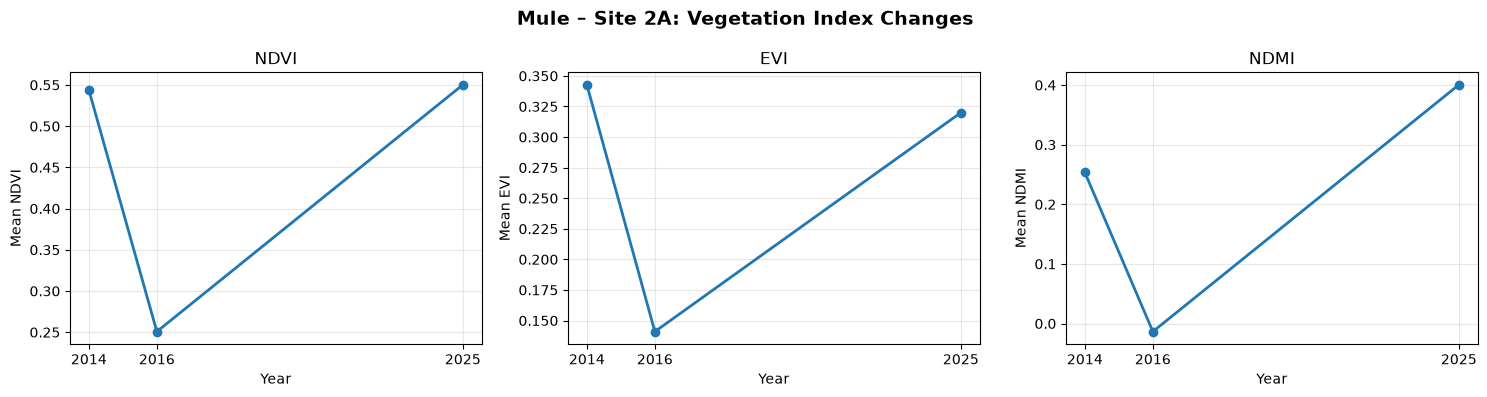

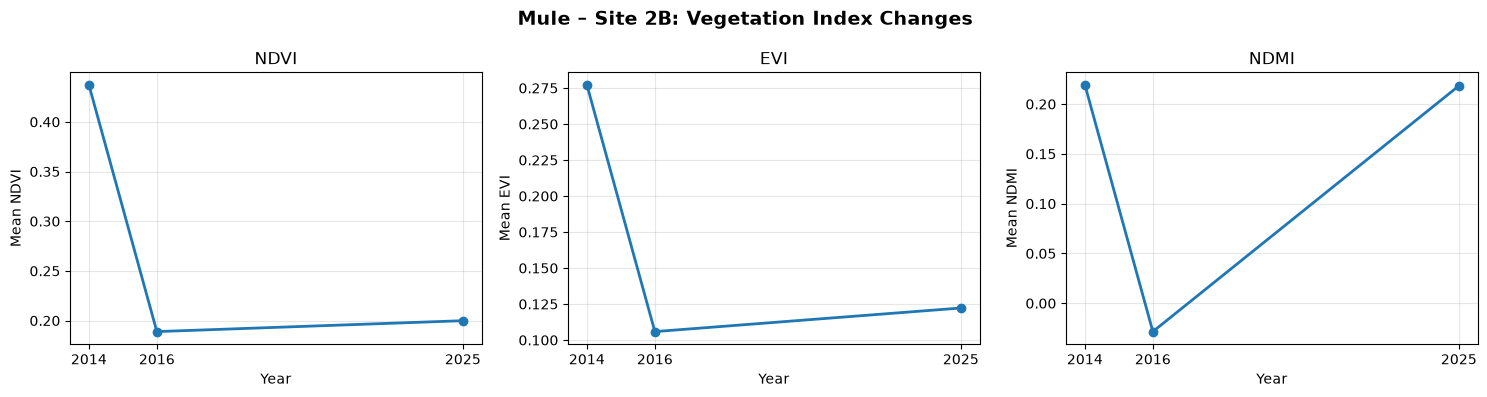

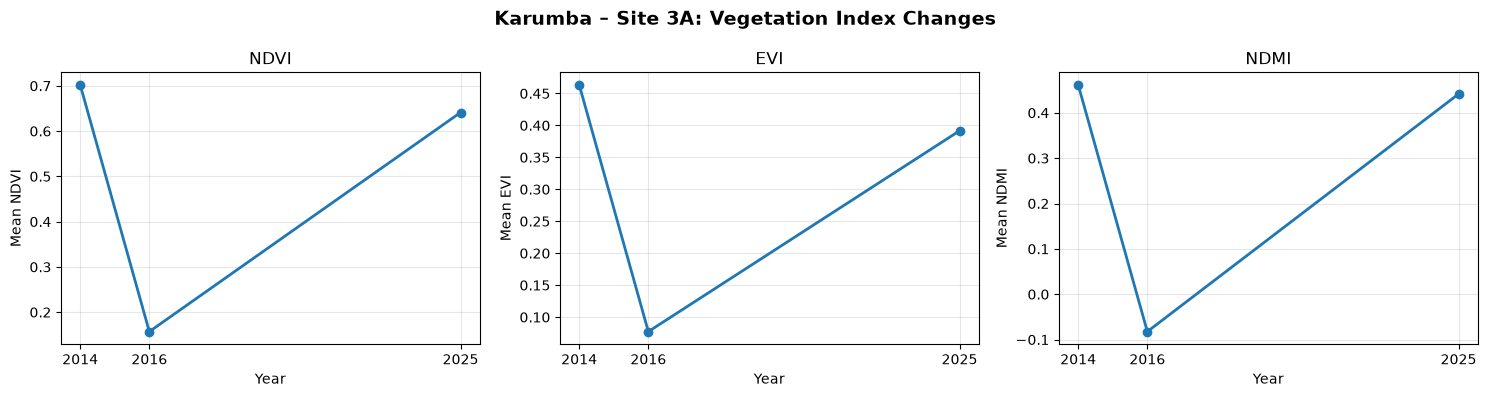

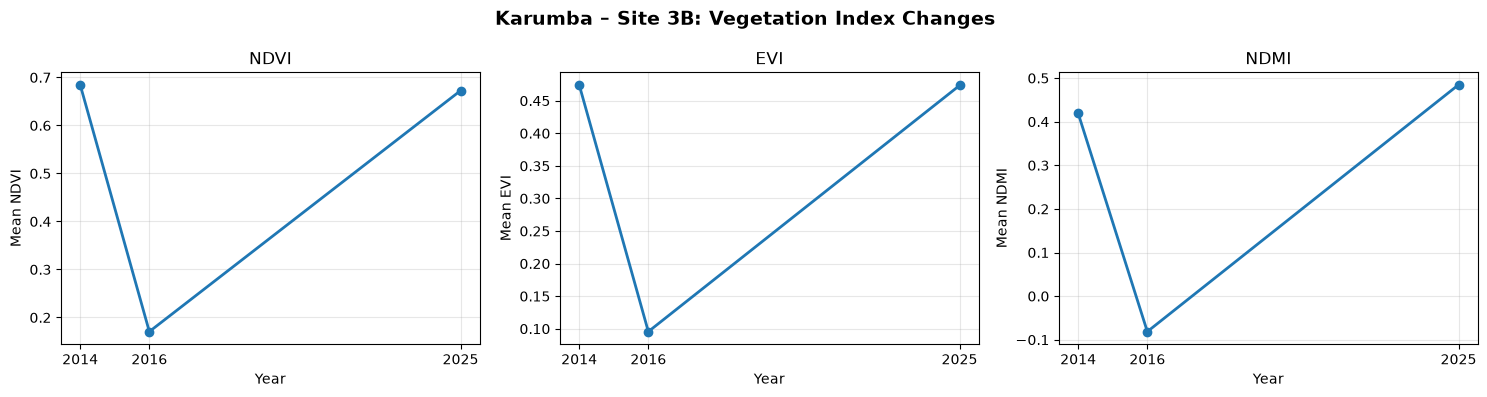

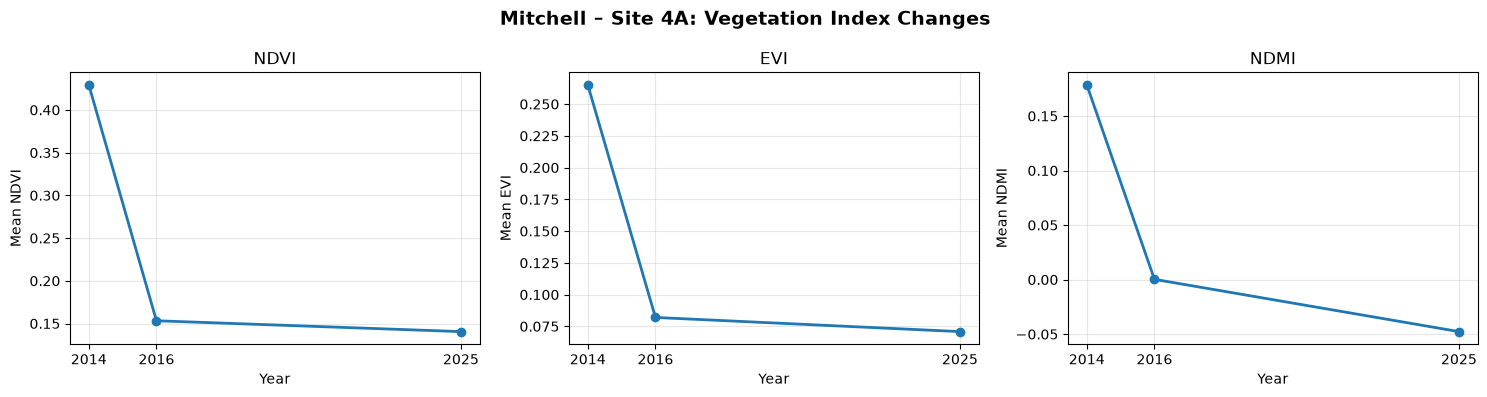

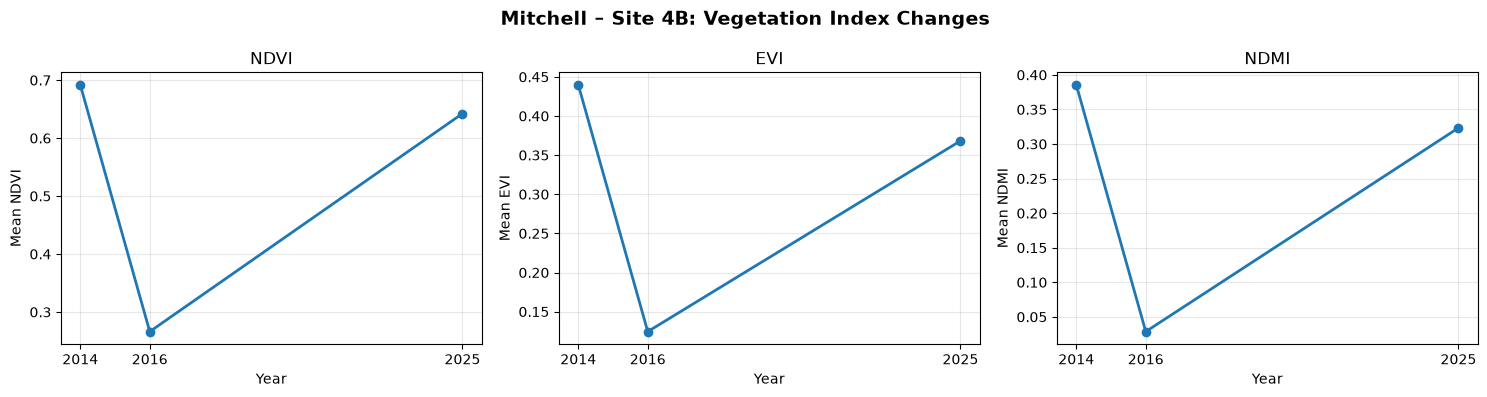

In [28]:
# Plot vegetation indices for each observation site

indices = ["NDVI", "EVI", "NDMI"]
years = [2014, 2016, 2025]

for site_code in index_table["Site_Code"].unique():

    site_data_plot = (
        index_table[
            index_table["Site_Code"] == site_code
        ].sort_values("Year")
    )

    location = site_data_plot["Location"].iloc[0]

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4),
        sharex=True
    )

    for ax, index in zip(axes, indices):

        ax.plot(
            site_data_plot["Year"],
            site_data_plot[index],
            marker="o",
            linewidth=2
        )

        ax.set_title(index)
        ax.set_xlabel("Year")
        ax.set_ylabel("Mean " + index)
        ax.set_xticks(years)
        ax.grid(True, alpha=0.3)

    fig.suptitle(
        f"{location} – Site {site_code}: Vegetation Index Changes",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

## 6.2 Save each site figure

In [ ]:
# Create folder for site figures
plot_dir = output_dir / "site_vegetation_plots"
plot_dir.mkdir(exist_ok=True)

for site_code in index_table["Site_Code"].unique():

    site_data_plot = (
        index_table[
            index_table["Site_Code"] == site_code
        ].sort_values("Year")
    )

    location = site_data_plot["Location"].iloc[0]

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4),
        sharex=True
    )

    for ax, index in zip(axes, indices):

        ax.plot(
            site_data_plot["Year"],
            site_data_plot[index],
            marker="o",
            linewidth=2
        )

        ax.set_title(index)
        ax.set_xlabel("Year")
        ax.set_ylabel("Mean " + index)
        ax.set_xticks(years)
        ax.grid(True, alpha=0.3)

    fig.suptitle(
        f"{location} – Site {site_code}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()

    fig.savefig(
        plot_dir / f"Site_{site_code}_vegetation_indices.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("All eight site figures saved in:", plot_dir.resolve())

# 7 Extract rainfall data using CHIRPS
CHIRPS Daily is the daily precipitation product from the Climate Hazards Center Infrared Precipitation with Stations dataset, produced by the Climate Hazards Center at UC Santa Barbara. It combines satellite-derived rainfall information with rain-gauge observations to provide a long, spatially consistent precipitation record over land.
Each grid cell represents daily accumulated precipitation, generally expressed in millimeters. Current CHIRPS v3 has a 0.05° grid (roughly 5–6 km near the equator), covers land from 60°S to 60°N, and extends from 1981 to near-present, making it particularly useful when both relatively fine spatial detail and a multi-decade baseline are needed.

## 7.1 Define the rainfall periods
We will extract rainfall for two periods for each study year:
1. Wet season (November–April): The six months preceding the June observation period.
2. Landsat observation season (June–October): The period corresponding to our vegetation-index composites.
For example, for the 2016 observation, the preceding wet season is November 2015–April 2016.

## 7.2 Load the CHIRPS dataset

In [29]:
# Load CHIRPS daily rainfall data
chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")

# Restrict the collection to the observation sites
chirps = chirps.filterBounds(sites.geometry())

print("CHIRPS dataset loaded successfully.")

CHIRPS dataset loaded successfully.


## 7.3 Check rainfall data availability

In [37]:
# Check available daily rainfall observations
rainfall_periods = {}

for year in years:

    rainfall_periods[year] = {
        "Wet_Season": (
            f"{year - 1}-11-01",
            f"{year}-05-01"
        ),
        "Observation_Season": (
            f"{year}-06-01",
            f"{year}-11-01"
        )
    }

for year in years:

    print(f"\nYear: {year}")

    for period, dates in rainfall_periods[year].items():

        collection = chirps.filterDate(
            dates[0], dates[1]
        )

        print(
            f"{period}: {collection.size().getInfo()} daily images"
        )


Year: 2014
Wet_Season: 181 daily images
Observation_Season: 153 daily images

Year: 2016
Wet_Season: 182 daily images
Observation_Season: 153 daily images

Year: 2025
Wet_Season: 181 daily images
Observation_Season: 153 daily images


## 7.4 Extract rainfall statistics at each site
Instead of using the 90 × 90 m polygons, we extract the CHIRPS pixel containing each site's centre coordinates.

For each period, we calculate:
- Total rainfall (mm).
- Mean daily rainfall (mm/day).
- Number of valid daily observations.

In [38]:
# Extract CHIRPS rainfall statistics for the eight sites

rainfall_results = []

# CHIRPS approximate spatial resolution
rainfall_scale = 5566

for year in years:

    for period, dates in rainfall_periods[year].items():

        print(f"Processing {year} - {period}")

        # Filter daily rainfall images
        collection = (
            chirps
            .filterDate(dates[0], dates[1])
            .select("precipitation")
        )

        # Calculate rainfall statistics
        rainfall_image = ee.Image.cat([

            collection.sum().rename(
                "Total_Rainfall_mm"
            ),

            collection.mean().rename(
                "Mean_Daily_Rainfall_mm"
            ),

            collection.count().rename(
                "Valid_Days"
            )

        ])

        # Extract rainfall for each site
        for location, state, code, lon, lat in site_data:

            # Site-centre point
            point = ee.Geometry.Point(
                [lon, lat]
            )

            # Extract pixel values
            values = rainfall_image.reduceRegion(
                reducer=ee.Reducer.first(),
                geometry=point,
                scale=rainfall_scale,
                maxPixels=1e6
            ).getInfo()

            # Store results
            rainfall_results.append({

                "Location": location,
                "State": state,
                "Site_Code": code,
                "Longitude": lon,
                "Latitude": lat,
                "Year": year,
                "Period": period,
                "Start_Date": dates[0],
                "End_Date": dates[1],

                "Total_Rainfall_mm":
                    values.get("Total_Rainfall_mm"),

                "Mean_Daily_Rainfall_mm":
                    values.get("Mean_Daily_Rainfall_mm"),

                "Valid_Days":
                    values.get("Valid_Days")

            })

print("\nRainfall extraction completed.")

Processing 2014 - Wet_Season
Processing 2014 - Observation_Season
Processing 2016 - Wet_Season
Processing 2016 - Observation_Season
Processing 2025 - Wet_Season
Processing 2025 - Observation_Season

Rainfall extraction completed.


## 7.5 Create and inspect the rainfall table

In [39]:
# Convert extraction results into a DataFrame

rainfall_table = pd.DataFrame(
    rainfall_results
)

# Convert numerical fields
numeric_columns = [
    "Total_Rainfall_mm",
    "Mean_Daily_Rainfall_mm",
    "Valid_Days"
]

for column in numeric_columns:

    rainfall_table[column] = pd.to_numeric(
        rainfall_table[column],
        errors="coerce"
    )

# Display results
display(
    rainfall_table.round(2)
)

# Check records and missing values
print("\nNumber of records:", len(rainfall_table))

print("\nMissing values:")
print(
    rainfall_table[numeric_columns].isna().sum()
)

,Location,State,Site_Code,Longitude,Latitude,Year,Period,Start_Date,End_Date,Total_Rainfall_mm,Mean_Daily_Rainfall_mm,Valid_Days
0,Limmen,NT,1A,135.79,-15.15,2014,Wet_Season,2013-11-01,2014-05-01,1171.82,6.47,181
1,Limmen,NT,1B,135.84,-15.17,2014,Wet_Season,2013-11-01,2014-05-01,1193.41,6.59,181
2,Mule,NT,2A,136.43,-15.65,2014,Wet_Season,2013-11-01,2014-05-01,1083.98,5.99,181
3,Mule,NT,2B,136.44,-15.65,2014,Wet_Season,2013-11-01,2014-05-01,1074.34,5.94,181
4,Karumba,QLD,3A,140.85,-17.42,2014,Wet_Season,2013-11-01,2014-05-01,819.71,4.53,181
5,Karumba,QLD,3B,140.90,-17.34,2014,Wet_Season,2013-11-01,2014-05-01,828.00,4.57,181
6,Mitchell,QLD,4A,141.67,-15.03,2014,Wet_Season,2013-11-01,2014-05-01,1578.56,8.72,181
7,Mitchell,QLD,4B,141.66,-15.00,2014,Wet_Season,2013-11-01,2014-05-01,1690.23,9.34,181
8,Limmen,NT,1A,135.79,-15.15,2014,Observation_Season,2014-06-01,2014-11-01,8.90,0.06,153
9,Limmen,NT,1B,135.84,-15.17,2014,Observation_Season,2014-06-01,2014-11-01,8.95,0.06,153



Number of records: 48

Missing values:
Total_Rainfall_mm         0
Mean_Daily_Rainfall_mm    0
Valid_Days                0
dtype: int64


## 7.6 Save the rainfall results

In [40]:
# Save rainfall results as CSV

rainfall_file = (
    output_dir / "mangrove_rainfall_CHIRPS.csv"
)

rainfall_table.to_csv(
    rainfall_file,
    index=False
)

print("Rainfall table saved successfully:")
print(rainfall_file.resolve())

Rainfall table saved successfully:
C:\Users\percy\Documents\studies\visual_studio_code\EOS\notebook\mangrove_outputs\mangrove_rainfall_CHIRPS.csv


## 7.7 Plot rainfall for each site

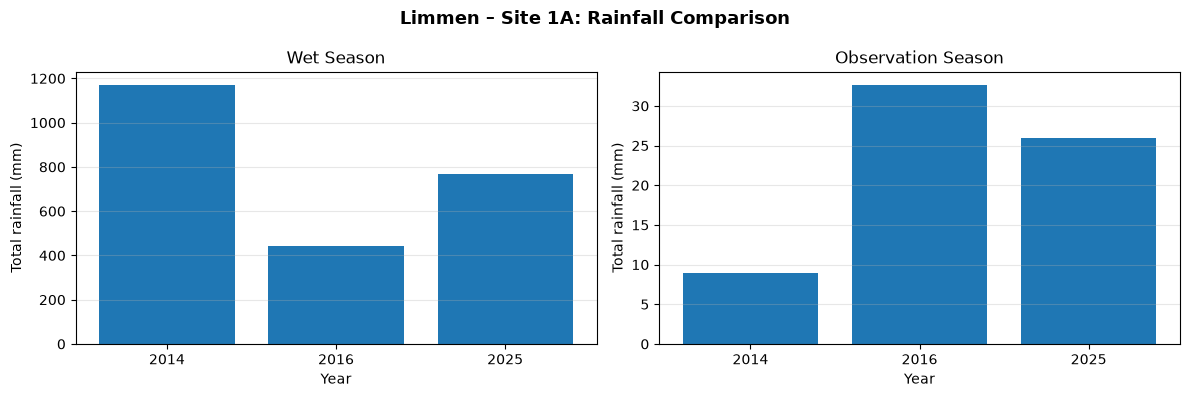

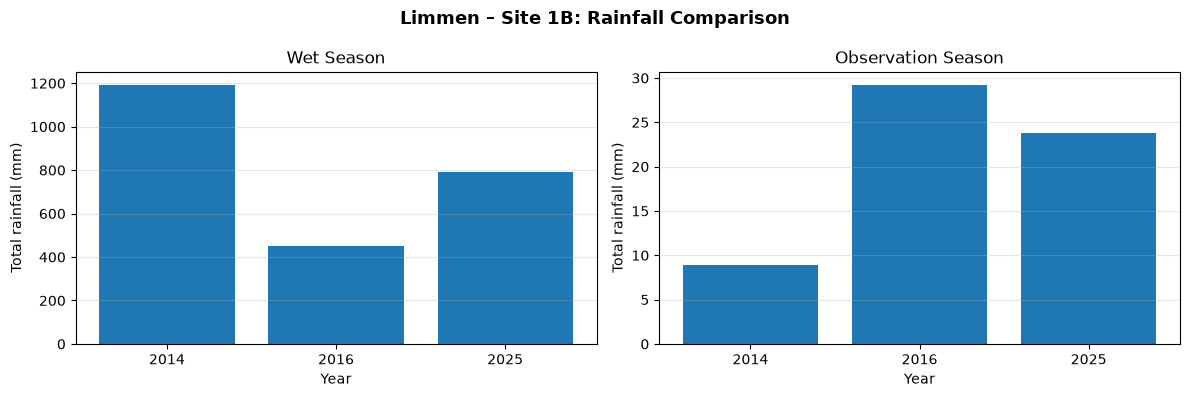

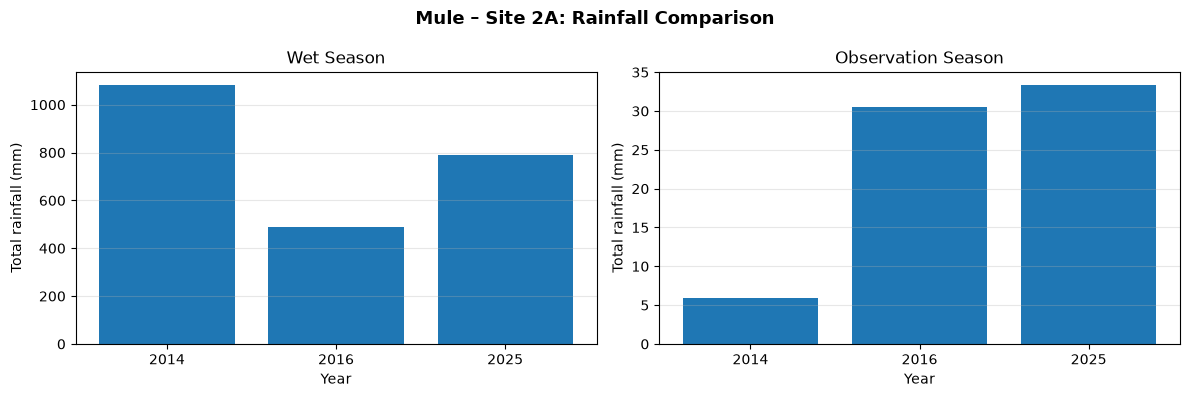

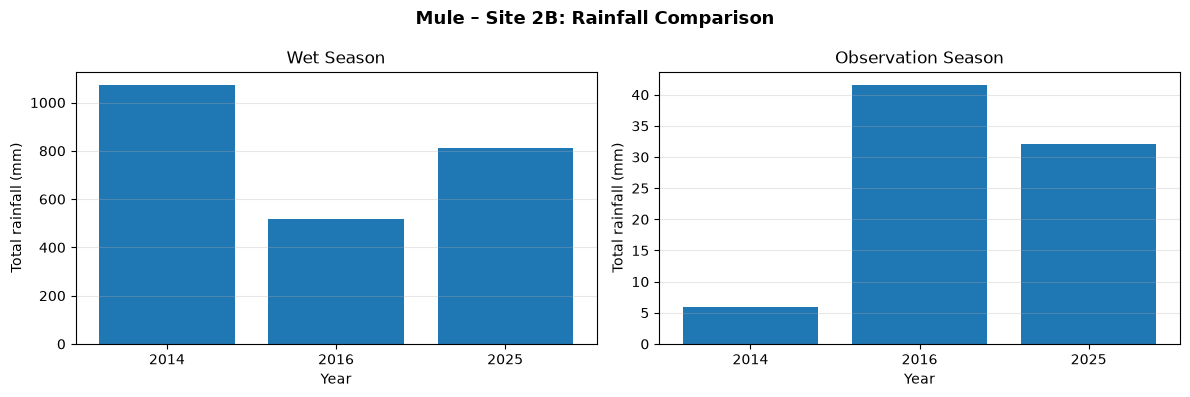

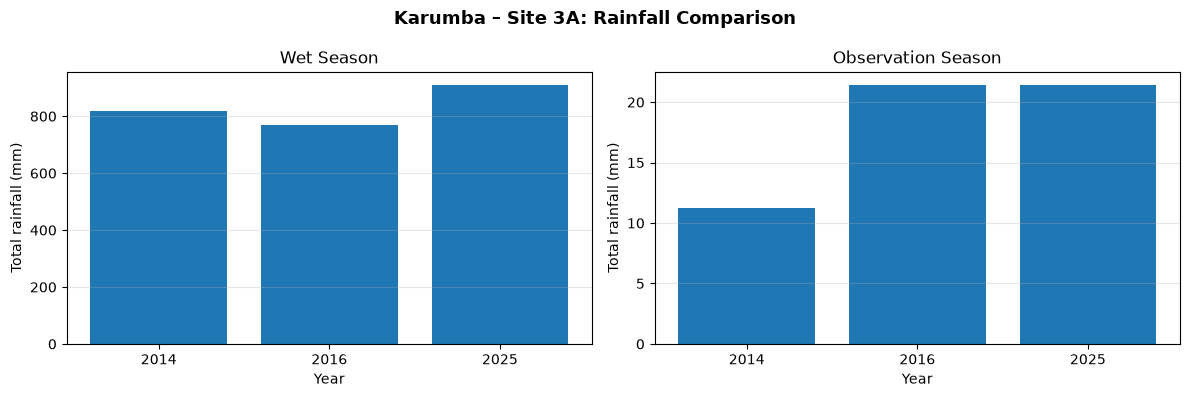

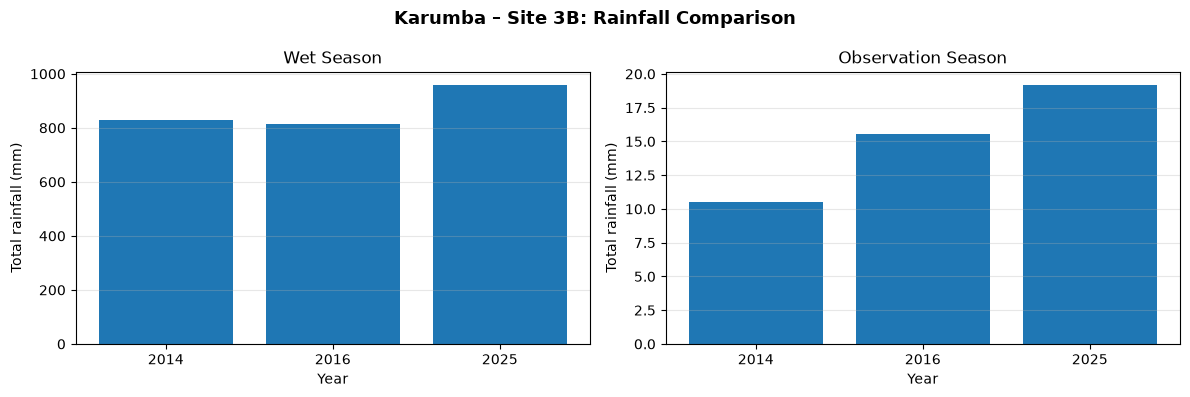

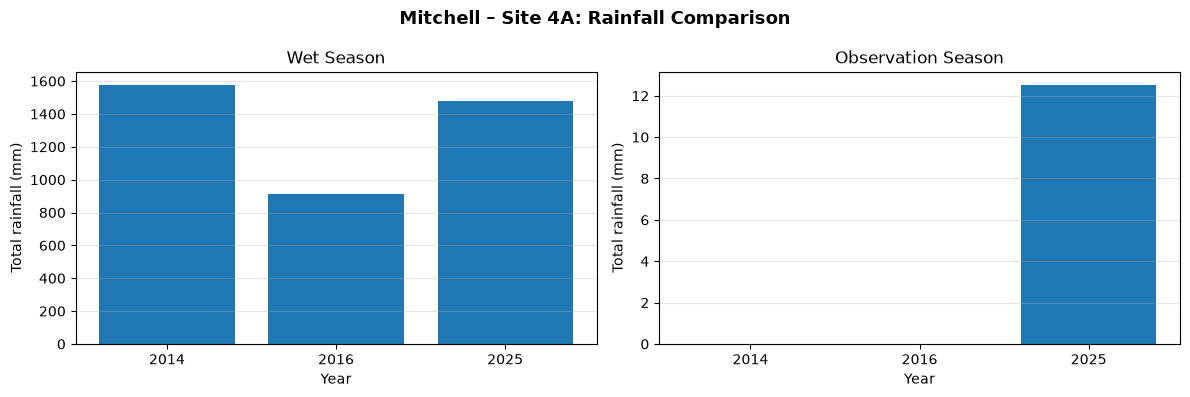

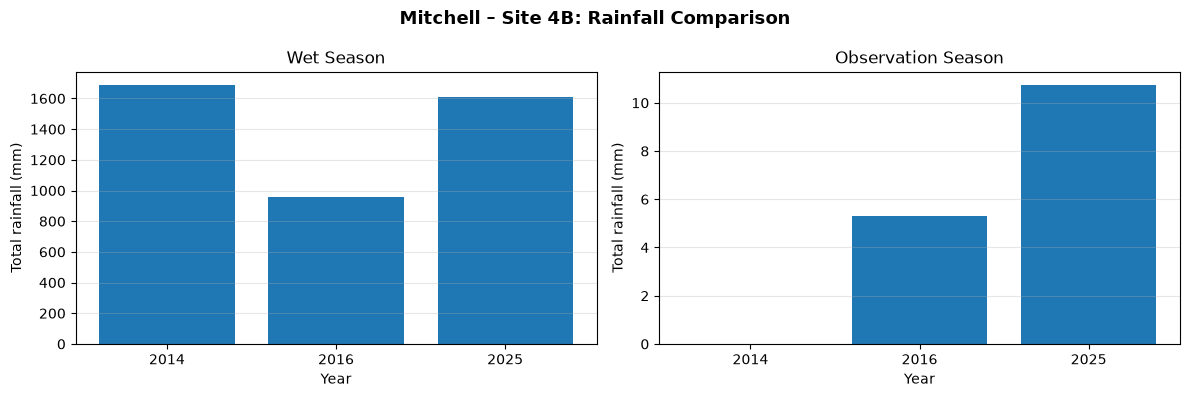


All rainfall figures saved in: C:\Users\percy\Documents\studies\visual_studio_code\EOS\notebook\mangrove_outputs\rainfall_plots


In [41]:
# Create output folder for rainfall figures

rainfall_plot_dir = (
    output_dir / "rainfall_plots"
)

rainfall_plot_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Plot rainfall for each site

for site_code in rainfall_table["Site_Code"].unique():

    site_rainfall = rainfall_table[
        rainfall_table["Site_Code"] == site_code
    ].copy()

    location = site_rainfall["Location"].iloc[0]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4)
    )

    periods = [
        "Wet_Season",
        "Observation_Season"
    ]

    for ax, period in zip(axes, periods):

        period_data = site_rainfall[
            site_rainfall["Period"] == period
        ].sort_values("Year")

        period_data = period_data.dropna(
            subset=["Total_Rainfall_mm"]
        )

        ax.bar(
            period_data["Year"].astype(str),
            period_data["Total_Rainfall_mm"]
        )

        ax.set_title(
            period.replace("_", " ")
        )

        ax.set_xlabel("Year")

        ax.set_ylabel(
            "Total rainfall (mm)"
        )

        ax.grid(
            axis="y",
            alpha=0.3
        )

    fig.suptitle(
        f"{location} – Site {site_code}: Rainfall Comparison",
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()

    # Save figure
    fig.savefig(
        rainfall_plot_dir /
        f"Rainfall_Site_{site_code}.png",

        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

print(
    "\nAll rainfall figures saved in:",
    rainfall_plot_dir.resolve()
)

# 8 Extract temperature data using ERA5-Land
Now we will investigate temperature conditions at the eight mangrove observation sites using the ERA5-Land Daily Aggregated available in Google Earth Engine.

This will complement the CHIRPS rainfall analysis from Step 7.

Dataset: ECMWF/ERA5_LAND/DAILY_AGGR

Spatial resolution: approximately 11 km · Original temperature unit: Kelvin (K) · Output unit: degrees Celsius (°C)

We will extract three temperature indicators:
1. Mean daily air temperature (°C).
2. Mean daily maximum air temperature (°C).
3. Highest daily maximum temperature during each period (°C).
We will use the same periods as the rainfall analysis:
- Wet season: November–April.
- Observation season: June–October.
For example, the 2016 wet season covers November 2015 to April 2016.

## 8.1 Load the ERA5-Land dataset

In [42]:
# Load ERA5-Land daily aggregated data
era5 = ee.ImageCollection(
    "ECMWF/ERA5_LAND/DAILY_AGGR"
)

# Filter to the study sites
era5 = era5.filterBounds(
    sites.geometry()
)

print("ERA5-Land dataset loaded successfully.")

# Inspect available bands
band_names = era5.first().bandNames().getInfo()

print("\nAvailable bands:")
print(band_names)

ERA5-Land dataset loaded successfully.

Available bands:
['dewpoint_temperature_2m', 'temperature_2m', 'skin_temperature', 'soil_temperature_level_1', 'soil_temperature_level_2', 'soil_temperature_level_3', 'soil_temperature_level_4', 'lake_bottom_temperature', 'lake_ice_depth', 'lake_ice_temperature', 'lake_mix_layer_depth', 'lake_mix_layer_temperature', 'lake_shape_factor', 'lake_total_layer_temperature', 'snow_albedo', 'snow_cover', 'snow_density', 'snow_depth', 'snow_depth_water_equivalent', 'snowfall_sum', 'snowmelt_sum', 'temperature_of_snow_layer', 'skin_reservoir_content', 'volumetric_soil_water_layer_1', 'volumetric_soil_water_layer_2', 'volumetric_soil_water_layer_3', 'volumetric_soil_water_layer_4', 'forecast_albedo', 'surface_latent_heat_flux_sum', 'surface_net_solar_radiation_sum', 'surface_net_thermal_radiation_sum', 'surface_sensible_heat_flux_sum', 'surface_solar_radiation_downwards_sum', 'surface_thermal_radiation_downwards_sum', 'evaporation_from_bare_soil_sum', 'evap

## 8.2 Check temperature data availability

In [43]:
# Check daily temperature observations for each period

for year in years:

    print(f"\nStudy year: {year}")

    for period, dates in rainfall_periods[year].items():

        collection = era5.filterDate(
            dates[0], dates[1]
        )

        image_count = collection.size().getInfo()

        print(
            f"{period}: {image_count} daily images"
        )


Study year: 2014
Wet_Season: 181 daily images
Observation_Season: 153 daily images

Study year: 2016
Wet_Season: 182 daily images
Observation_Season: 153 daily images

Study year: 2025
Wet_Season: 181 daily images
Observation_Season: 153 daily images


## 8.3 Extract temperature statistics for each site

In [61]:
temperature_results = []
temperature_scale = 11132

for year in years:
    for period, dates in rainfall_periods[year].items():

        collection = era5.filterDate(dates[0], dates[1])

        temperature_image = ee.Image.cat([
            collection.select("temperature_2m")
                .mean()
                .rename("Mean_Temperature_K"),

            collection.select("temperature_2m_max")
                .mean()
                .rename("Mean_Daily_Max_Temperature_K"),

            collection.select("temperature_2m_max")
                .max()
                .rename("Period_Max_Temperature_K"),

            collection.select("temperature_2m")
                .count()
                .rename("Valid_Days")
        ])

        for location, state, code, lon, lat in site_data:

            point = ee.Geometry.Point([lon, lat])
            site_buffer = point.buffer(6000)

            values = temperature_image.reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=site_buffer,
                scale=temperature_scale,
                maxPixels=1e6
            ).getInfo()

            temperature_results.append({
                "Location": location,
                "State": state,
                "Site_Code": code,
                "Longitude": lon,
                "Latitude": lat,
                "Year": year,
                "Period": period,
                "Start_Date": dates[0],
                "End_Date": dates[1],
                "Mean_Temperature_K": values.get("Mean_Temperature_K"),
                "Mean_Daily_Max_Temperature_K": values.get("Mean_Daily_Max_Temperature_K"),
                "Period_Max_Temperature_K": values.get("Period_Max_Temperature_K"),
                "Valid_Days": values.get("Valid_Days")
            })

temperature_table = pd.DataFrame(temperature_results)

# Convert columns to numeric
for column in [
    "Mean_Temperature_K",
    "Mean_Daily_Max_Temperature_K",
    "Period_Max_Temperature_K",
    "Valid_Days"
]:
    temperature_table[column] = pd.to_numeric(
        temperature_table[column], errors="coerce"
    )

# Convert Kelvin to Celsius
temperature_table["Mean_Temperature_C"] = (
    temperature_table["Mean_Temperature_K"] - 273.15
)

temperature_table["Mean_Daily_Max_Temperature_C"] = (
    temperature_table["Mean_Daily_Max_Temperature_K"] - 273.15
)

temperature_table["Period_Max_Temperature_C"] = (
    temperature_table["Period_Max_Temperature_K"] - 273.15
)

display(temperature_table)

,Location,State,Site_Code,Longitude,Latitude,Year,Period,Start_Date,End_Date,Mean_Temperature_K,Mean_Daily_Max_Temperature_K,Period_Max_Temperature_K,Valid_Days,Mean_Temperature_C,Mean_Daily_Max_Temperature_C,Period_Max_Temperature_C
0,Limmen,NT,1A,135.78877,-15.14622,2014,Wet_Season,2013-11-01,2014-05-01,301.386756,304.280271,309.696075,181,28.236756,31.130271,36.546075
1,Limmen,NT,1B,135.83699,-15.17115,2014,Wet_Season,2013-11-01,2014-05-01,301.377380,304.409260,309.880630,181,28.227380,31.259260,36.730630
2,Mule,NT,2A,136.43415,-15.64737,2014,Wet_Season,2013-11-01,2014-05-01,301.484347,303.644691,308.842974,181,28.334347,30.494691,35.692974
3,Mule,NT,2B,136.44197,-15.65092,2014,Wet_Season,2013-11-01,2014-05-01,301.490811,303.620796,308.783405,181,28.340811,30.470796,35.633405
4,Karumba,QLD,3A,140.85358,-17.42256,2014,Wet_Season,2013-11-01,2014-05-01,301.639553,304.390423,312.535225,181,28.489553,31.240423,39.385225
5,Karumba,QLD,3B,140.89625,-17.34002,2014,Wet_Season,2013-11-01,2014-05-01,301.639483,304.462144,312.334690,181,28.489483,31.312144,39.184690
6,Mitchell,QLD,4A,141.66542,-15.02732,2014,Wet_Season,2013-11-01,2014-05-01,301.100468,304.906252,310.814891,181,27.950468,31.756252,37.664891
7,Mitchell,QLD,4B,141.66092,-14.99654,2014,Wet_Season,2013-11-01,2014-05-01,301.088223,304.850785,310.651692,181,27.938223,31.700785,37.501692
8,Limmen,NT,1A,135.78877,-15.14622,2014,Observation_Season,2014-06-01,2014-11-01,296.572675,301.378046,306.696121,153,23.422675,28.228046,33.546121
9,Limmen,NT,1B,135.83699,-15.17115,2014,Observation_Season,2014-06-01,2014-11-01,296.539015,301.640208,307.004156,153,23.389015,28.490208,33.854156


In [62]:
# Check the results
print("Missing temperature records:",
      temperature_table["Mean_Temperature_C"].isna().sum())

display(
    temperature_table[
        temperature_table["Mean_Temperature_C"].isna()
    ][["Location", "Site_Code", "Year", "Period"]]
)

Missing temperature records: 0


,Location,Site_Code,Year,Period


## 8.4 Convert temperature from Kelvin to Celsius

In [63]:
# Create temperature DataFrame
temperature_table = pd.DataFrame(
    temperature_results
)

# Convert temperature fields to numeric
temperature_columns = [
    "Mean_Temperature_K",
    "Mean_Daily_Max_Temperature_K",
    "Period_Max_Temperature_K",
    "Valid_Days"
]

for column in temperature_columns:

    temperature_table[column] = pd.to_numeric(
        temperature_table[column],
        errors="coerce"
    )

# Convert Kelvin to Celsius
temperature_table["Mean_Temperature_C"] = (
    temperature_table["Mean_Temperature_K"] - 273.15
)

temperature_table["Mean_Daily_Max_Temperature_C"] = (
    temperature_table["Mean_Daily_Max_Temperature_K"] - 273.15
)

temperature_table["Period_Max_Temperature_C"] = (
    temperature_table["Period_Max_Temperature_K"] - 273.15
)

# Display results
display(temperature_table.round(2))

,Location,State,Site_Code,Longitude,Latitude,Year,Period,Start_Date,End_Date,Mean_Temperature_K,Mean_Daily_Max_Temperature_K,Period_Max_Temperature_K,Valid_Days,Mean_Temperature_C,Mean_Daily_Max_Temperature_C,Period_Max_Temperature_C
0,Limmen,NT,1A,135.79,-15.15,2014,Wet_Season,2013-11-01,2014-05-01,301.39,304.28,309.70,181,28.24,31.13,36.55
1,Limmen,NT,1B,135.84,-15.17,2014,Wet_Season,2013-11-01,2014-05-01,301.38,304.41,309.88,181,28.23,31.26,36.73
2,Mule,NT,2A,136.43,-15.65,2014,Wet_Season,2013-11-01,2014-05-01,301.48,303.64,308.84,181,28.33,30.49,35.69
3,Mule,NT,2B,136.44,-15.65,2014,Wet_Season,2013-11-01,2014-05-01,301.49,303.62,308.78,181,28.34,30.47,35.63
4,Karumba,QLD,3A,140.85,-17.42,2014,Wet_Season,2013-11-01,2014-05-01,301.64,304.39,312.54,181,28.49,31.24,39.39
5,Karumba,QLD,3B,140.90,-17.34,2014,Wet_Season,2013-11-01,2014-05-01,301.64,304.46,312.33,181,28.49,31.31,39.18
6,Mitchell,QLD,4A,141.67,-15.03,2014,Wet_Season,2013-11-01,2014-05-01,301.10,304.91,310.81,181,27.95,31.76,37.66
7,Mitchell,QLD,4B,141.66,-15.00,2014,Wet_Season,2013-11-01,2014-05-01,301.09,304.85,310.65,181,27.94,31.70,37.50
8,Limmen,NT,1A,135.79,-15.15,2014,Observation_Season,2014-06-01,2014-11-01,296.57,301.38,306.70,153,23.42,28.23,33.55
9,Limmen,NT,1B,135.84,-15.17,2014,Observation_Season,2014-06-01,2014-11-01,296.54,301.64,307.00,153,23.39,28.49,33.85


## 8.5 Check data completeness

In [64]:
# Check number of records
print(
    "Number of records:",
    len(temperature_table)
)

# Check missing values
print("\nMissing values:")
print(
    temperature_table[
        [
            "Mean_Temperature_C",
            "Mean_Daily_Max_Temperature_C",
            "Period_Max_Temperature_C",
            "Valid_Days"
        ]
    ].isna().sum()
)

# Check valid observation days
print("\nValid daily observations:")
display(
    temperature_table[
        ["Site_Code", "Year", "Period", "Valid_Days"]
    ]
)

Number of records: 48

Missing values:
Mean_Temperature_C              0
Mean_Daily_Max_Temperature_C    0
Period_Max_Temperature_C        0
Valid_Days                      0
dtype: int64

Valid daily observations:


,Site_Code,Year,Period,Valid_Days
0,1A,2014,Wet_Season,181
1,1B,2014,Wet_Season,181
2,2A,2014,Wet_Season,181
3,2B,2014,Wet_Season,181
4,3A,2014,Wet_Season,181
5,3B,2014,Wet_Season,181
6,4A,2014,Wet_Season,181
7,4B,2014,Wet_Season,181
8,1A,2014,Observation_Season,153
9,1B,2014,Observation_Season,153


## 8.6 Save the temperature results

In [65]:
# Save temperature results
temperature_file = (
    output_dir / "mangrove_temperature_ERA5_Land.csv"
)

temperature_table.to_csv(
    temperature_file,
    index=False
)

print("Temperature table saved successfully:")
print(temperature_file.resolve())

Temperature table saved successfully:
C:\Users\percy\Documents\studies\visual_studio_code\EOS\notebook\mangrove_outputs\mangrove_temperature_ERA5_Land.csv


## 8.7 Plot temperature for each observation site

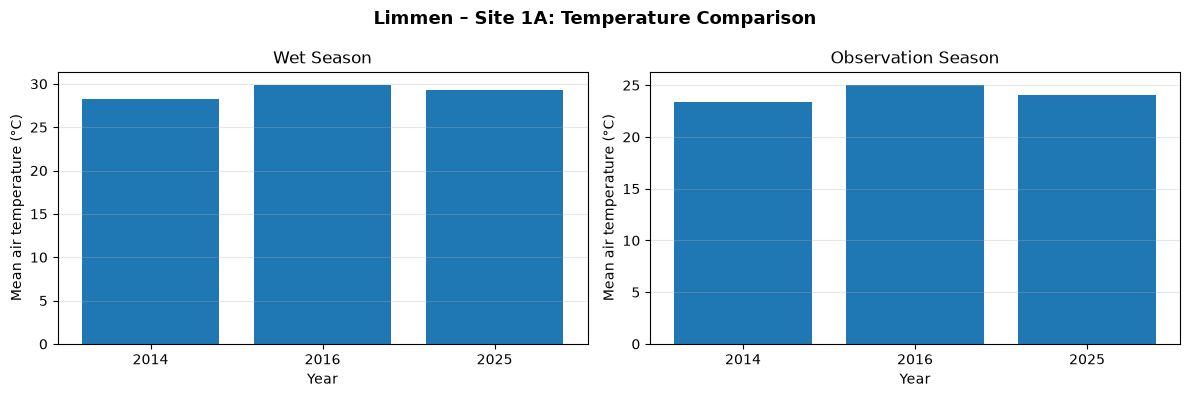

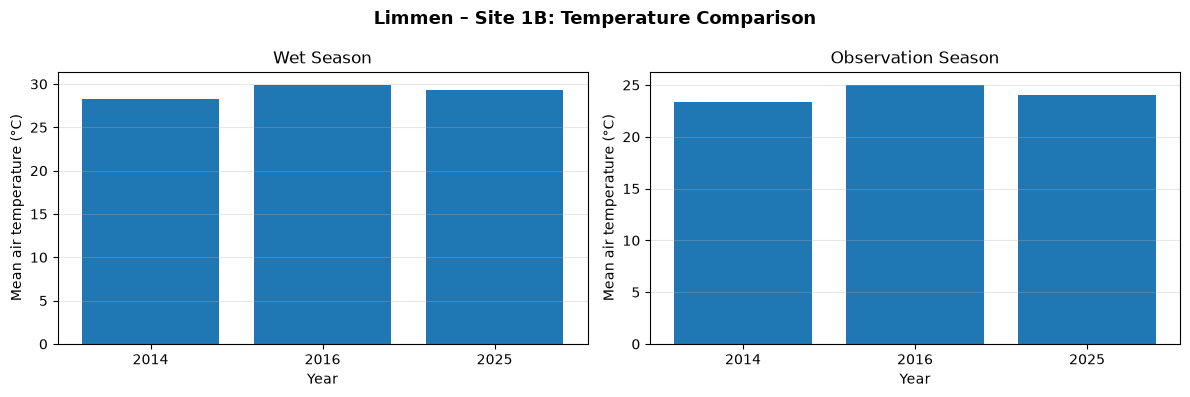

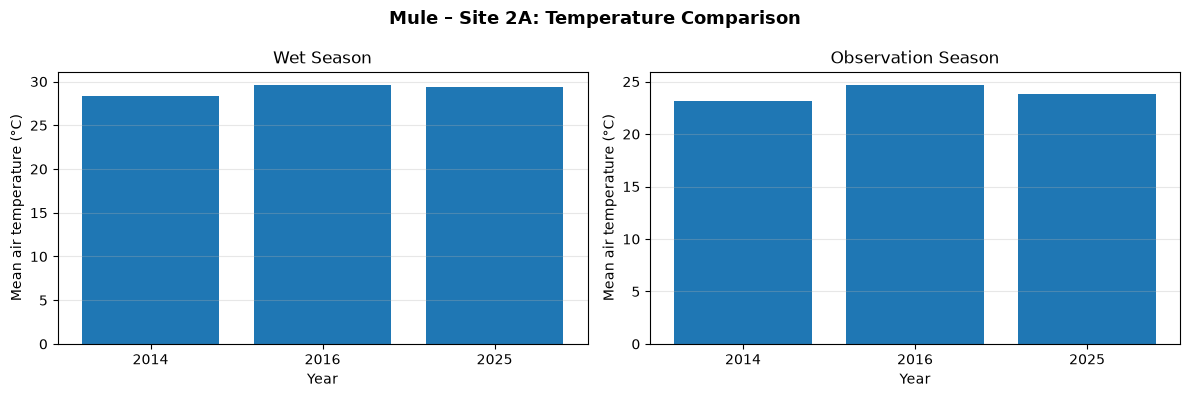

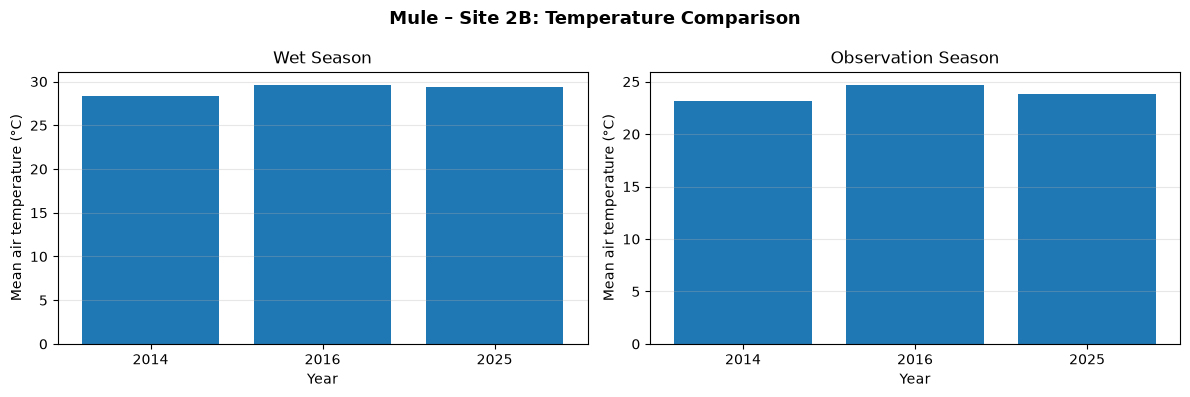

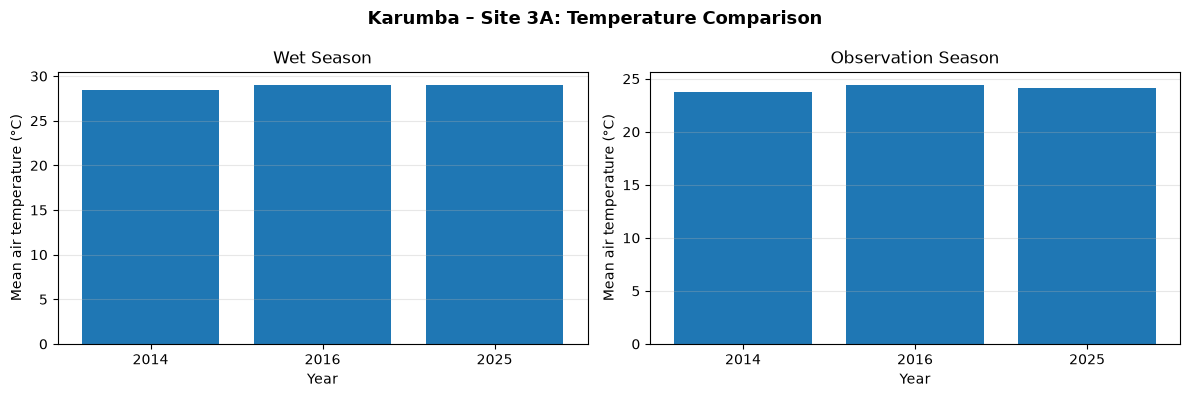

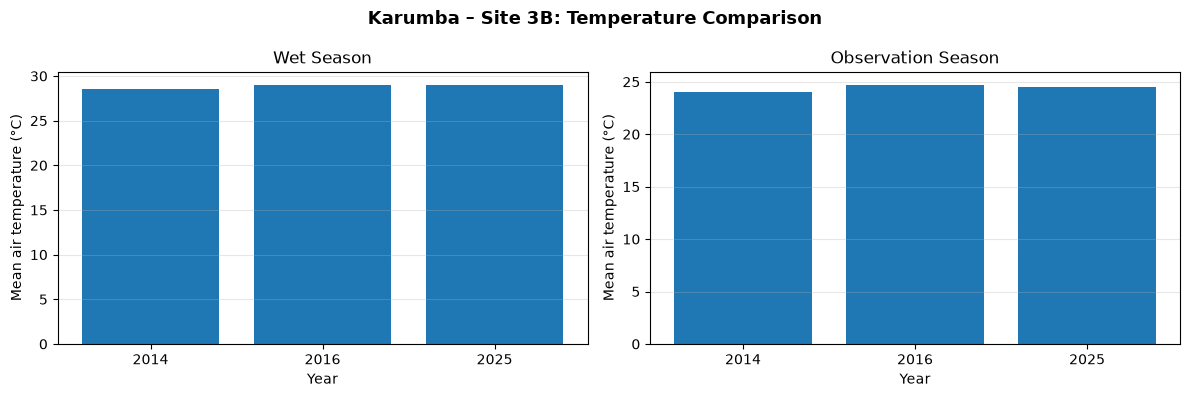

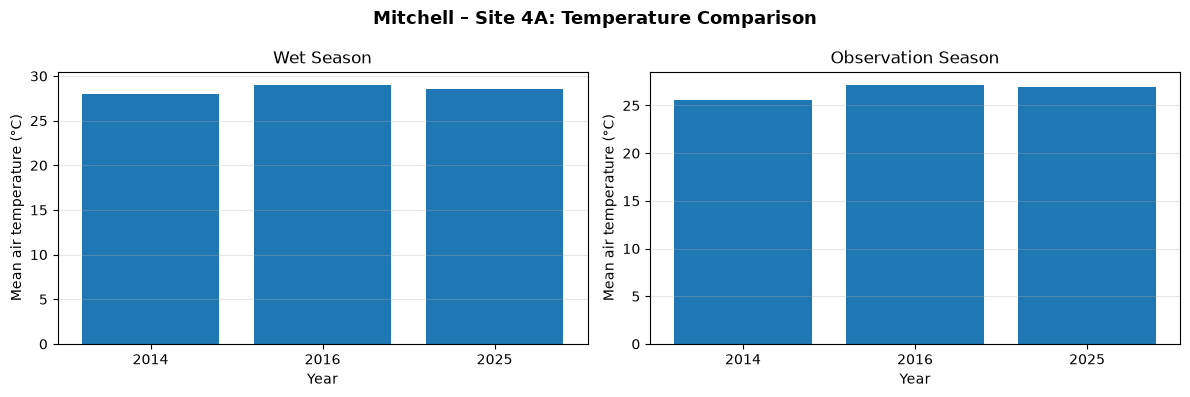

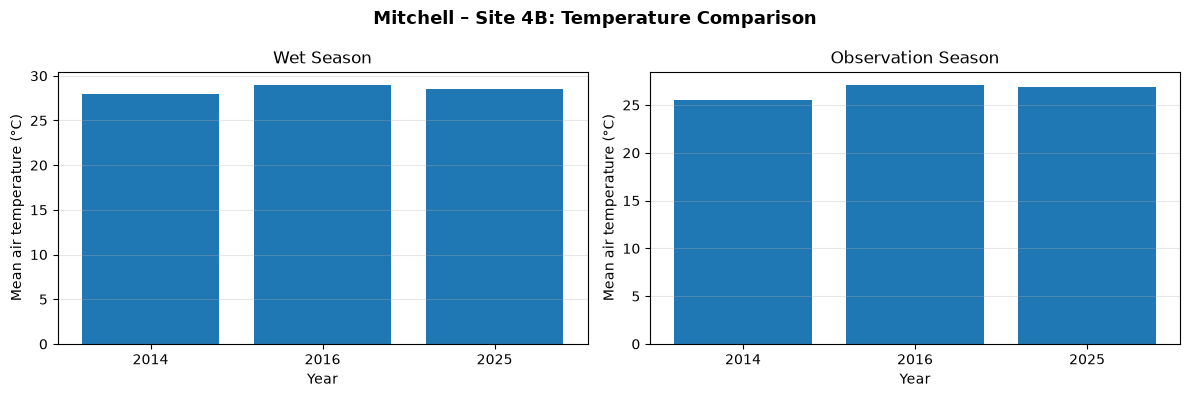

Temperature figures saved in: C:\Users\percy\Documents\studies\visual_studio_code\EOS\notebook\mangrove_outputs\temperature_plots


In [66]:
# Create output folder
temperature_plot_dir = (
    output_dir / "temperature_plots"
)

temperature_plot_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Temperature variable to plot
temperature_variable = "Mean_Temperature_C"

for site_code in temperature_table["Site_Code"].unique():

    site_temperature = temperature_table[
        temperature_table["Site_Code"] == site_code
    ].copy()

    location = site_temperature["Location"].iloc[0]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4)
    )

    periods = [
        "Wet_Season",
        "Observation_Season"
    ]

    for ax, period in zip(axes, periods):

        period_data = site_temperature[
            site_temperature["Period"] == period
        ].sort_values("Year")

        period_data = period_data.dropna(
            subset=[temperature_variable]
        )

        ax.bar(
            period_data["Year"].astype(str),
            period_data[temperature_variable]
        )

        ax.set_title(
            period.replace("_", " ")
        )

        ax.set_xlabel("Year")
        ax.set_ylabel("Mean air temperature (°C)")
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle(
        f"{location} – Site {site_code}: Temperature Comparison",
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()

    fig.savefig(
        temperature_plot_dir /
        f"Temperature_Site_{site_code}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print(
    "Temperature figures saved in:",
    temperature_plot_dir.resolve()
)

# 9 Integrate vegetation indices, rainfall and temperature
Now we will combine the three datasets developed in the previous steps:
1. Landsat: NDVI, EVI and NDMI.
2. CHIRPS: Total and mean daily rainfall.
3. ERA5-Land: Mean and maximum air temperature.
The objective is to create one integrated dataset that allows us to examine relationships between mangrove vegetation condition and environmental variables.

We will create two datasets:
- Long-format dataset: One record per site, year and climate period (48 records).
- Wide-format dataset: One record per site and year (24 records), with wet-season and observation-season climate variables in separate columns.

## 9.1 Check the three input datasets

In [67]:
# Check the three datasets

print("Vegetation indices:", len(index_table))
print("Rainfall records:", len(rainfall_table))
print("Temperature records:", len(temperature_table))

print("\nVegetation index columns:")
print(index_table.columns.tolist())

print("\nRainfall columns:")
print(rainfall_table.columns.tolist())

print("\nTemperature columns:")
print(temperature_table.columns.tolist())

Vegetation indices: 24
Rainfall records: 48
Temperature records: 48

Vegetation index columns:
['Location', 'Site_Code', 'Year', 'NDVI', 'EVI', 'NDMI']

Rainfall columns:
['Location', 'State', 'Site_Code', 'Longitude', 'Latitude', 'Year', 'Period', 'Start_Date', 'End_Date', 'Total_Rainfall_mm', 'Mean_Daily_Rainfall_mm', 'Valid_Days']

Temperature columns:
['Location', 'State', 'Site_Code', 'Longitude', 'Latitude', 'Year', 'Period', 'Start_Date', 'End_Date', 'Mean_Temperature_K', 'Mean_Daily_Max_Temperature_K', 'Period_Max_Temperature_K', 'Valid_Days', 'Mean_Temperature_C', 'Mean_Daily_Max_Temperature_C', 'Period_Max_Temperature_C']


## 9.2 Prepare the datasets for integration

In [68]:
# Common columns used to merge the datasets
join_columns = ["Location", "Site_Code", "Year"]

# Prepare vegetation dataset
vegetation_data = index_table[
    join_columns + ["NDVI", "EVI", "NDMI"]
].copy()

# Prepare rainfall dataset
rainfall_data = rainfall_table[
    join_columns + [
        "Period",
        "Total_Rainfall_mm",
        "Mean_Daily_Rainfall_mm",
        "Valid_Days"
    ]
].copy()

# Prepare temperature dataset
temperature_data = temperature_table[
    join_columns + [
        "Period",
        "Mean_Temperature_C",
        "Mean_Daily_Max_Temperature_C",
        "Period_Max_Temperature_C"
    ]
].copy()

# Ensure Year has the same data type in all datasets
for df in [vegetation_data, rainfall_data, temperature_data]:
    df["Year"] = df["Year"].astype(int)

print("Vegetation records:", len(vegetation_data))
print("Rainfall records:", len(rainfall_data))
print("Temperature records:", len(temperature_data))

Vegetation records: 24
Rainfall records: 48
Temperature records: 48


## 9.3 Combine rainfall and temperature

In [69]:
climate_data = pd.merge(
    rainfall_data,
    temperature_data,
    on=join_columns + ["Period"],
    how="outer",
    validate="one_to_one"
)

climate_data = climate_data.sort_values(
    ["Site_Code", "Year", "Period"]
).reset_index(drop=True)

display(climate_data.head())

,Location,Site_Code,Year,Period,Total_Rainfall_mm,Mean_Daily_Rainfall_mm,Valid_Days,Mean_Temperature_C,Mean_Daily_Max_Temperature_C,Period_Max_Temperature_C
0,Limmen,1A,2014,Observation_Season,8.899359,0.058166,153,23.422675,28.228046,33.546121
1,Limmen,1A,2014,Wet_Season,1171.820366,6.474146,181,28.236756,31.130271,36.546075
2,Limmen,1A,2016,Observation_Season,32.681320,0.213603,153,25.054032,29.347788,34.730615
3,Limmen,1A,2016,Wet_Season,441.433205,2.425457,182,29.910515,33.307991,37.735376
4,Limmen,1A,2025,Observation_Season,25.983825,0.169829,153,24.070070,28.665338,35.161111


## 9.4 Merge vegetation indices with climate data
This combines NDVI, EVI and NDMI with rainfall and temperature variables.

In [70]:
# Merge climate data with vegetation indices
environmental_data = pd.merge(
    climate_data,
    vegetation_data,
    on=join_columns,
    how="left",
    validate="many_to_one"
)

# Arrange columns
environmental_data = environmental_data[
    [
        "Location",
        "Site_Code",
        "Year",
        "Period",
        "NDVI",
        "EVI",
        "NDMI",
        "Total_Rainfall_mm",
        "Mean_Daily_Rainfall_mm",
        "Mean_Temperature_C",
        "Mean_Daily_Max_Temperature_C",
        "Period_Max_Temperature_C",
        "Valid_Days"
    ]
]

# Sort the dataset
environmental_data = environmental_data.sort_values(
    ["Site_Code", "Year", "Period"]
).reset_index(drop=True)

display(environmental_data.head(10))

,Location,Site_Code,Year,Period,NDVI,EVI,NDMI,Total_Rainfall_mm,Mean_Daily_Rainfall_mm,Mean_Temperature_C,Mean_Daily_Max_Temperature_C,Period_Max_Temperature_C,Valid_Days
0,Limmen,1A,2014,Observation_Season,0.684706,0.470975,0.445104,8.899359,0.058166,23.422675,28.228046,33.546121,153
1,Limmen,1A,2014,Wet_Season,0.684706,0.470975,0.445104,1171.820366,6.474146,28.236756,31.130271,36.546075,181
2,Limmen,1A,2016,Observation_Season,0.200283,0.108156,-0.054927,32.681320,0.213603,25.054032,29.347788,34.730615,153
3,Limmen,1A,2016,Wet_Season,0.200283,0.108156,-0.054927,441.433205,2.425457,29.910515,33.307991,37.735376,182
4,Limmen,1A,2025,Observation_Season,0.261270,0.170987,0.252652,25.983825,0.169829,24.070070,28.665338,35.161111,153
5,Limmen,1A,2025,Wet_Season,0.261270,0.170987,0.252652,767.752724,4.241728,29.316849,32.273720,38.823175,181
6,Limmen,1B,2014,Observation_Season,0.632384,0.433200,0.380995,8.948817,0.058489,23.389015,28.490208,33.854156,153
7,Limmen,1B,2014,Wet_Season,0.632384,0.433200,0.380995,1193.412304,6.593438,28.227380,31.259260,36.730630,181
8,Limmen,1B,2016,Observation_Season,0.221383,0.120314,-0.036176,29.250266,0.191178,25.034823,29.577300,35.032144,153
9,Limmen,1B,2016,Wet_Season,0.221383,0.120314,-0.036176,452.968484,2.488838,29.926924,33.518464,38.089218,182


## 9.5 Check data completeness

In [71]:
print("Total records:", len(environmental_data))
print("Number of sites:", environmental_data["Site_Code"].nunique())
print("Years:", sorted(environmental_data["Year"].unique()))
print("Periods:", environmental_data["Period"].unique())

print("\nMissing values:")
display(
    environmental_data.isna().sum().to_frame("Missing_Count")
)

print(
    "\nDuplicate site-year-period combinations:",
    environmental_data.duplicated(
        subset=join_columns + ["Period"]
    ).sum()
)

Total records: 48
Number of sites: 8
Years: [np.int64(2014), np.int64(2016), np.int64(2025)]
Periods: <StringArray>
['Observation_Season', 'Wet_Season']
Length: 2, dtype: str

Missing values:


,Missing_Count
Location,0
Site_Code,0
Year,0
Period,0
NDVI,0
EVI,0
NDMI,0
Total_Rainfall_mm,0
Mean_Daily_Rainfall_mm,0
Mean_Temperature_C,0



Duplicate site-year-period combinations: 0


## 9.6 Create a wide-format dataset

In [72]:
# Climate variables to reshape
climate_variables = [
    "Total_Rainfall_mm",
    "Mean_Daily_Rainfall_mm",
    "Mean_Temperature_C",
    "Mean_Daily_Max_Temperature_C",
    "Period_Max_Temperature_C"
]

# Reshape climate data
climate_wide = environmental_data.pivot(
    index=["Location", "Site_Code", "Year"],
    columns="Period",
    values=climate_variables
)

# Flatten the multi-level column names
climate_wide.columns = [
    f"{variable}_{period}"
    for variable, period in climate_wide.columns
]

climate_wide = climate_wide.reset_index()

# Merge climate variables with vegetation indices
environmental_wide = pd.merge(
    climate_wide,
    vegetation_data,
    on=join_columns,
    how="left",
    validate="one_to_one"
)

# Sort records
environmental_wide = environmental_wide.sort_values(
    ["Site_Code", "Year"]
).reset_index(drop=True)

display(environmental_wide.round(3))

,Location,Site_Code,Year,Total_Rainfall_mm_Observation_Season,Total_Rainfall_mm_Wet_Season,Mean_Daily_Rainfall_mm_Observation_Season,Mean_Daily_Rainfall_mm_Wet_Season,Mean_Temperature_C_Observation_Season,Mean_Temperature_C_Wet_Season,Mean_Daily_Max_Temperature_C_Observation_Season,Mean_Daily_Max_Temperature_C_Wet_Season,Period_Max_Temperature_C_Observation_Season,Period_Max_Temperature_C_Wet_Season,NDVI,EVI,NDMI
0,Limmen,1A,2014,8.899,1171.820,0.058,6.474,23.423,28.237,28.228,31.130,33.546,36.546,0.685,0.471,0.445
1,Limmen,1A,2016,32.681,441.433,0.214,2.425,25.054,29.911,29.348,33.308,34.731,37.735,0.200,0.108,-0.055
2,Limmen,1A,2025,25.984,767.753,0.170,4.242,24.070,29.317,28.665,32.274,35.161,38.823,0.261,0.171,0.253
3,Limmen,1B,2014,8.949,1193.412,0.058,6.593,23.389,28.227,28.490,31.259,33.854,36.731,0.632,0.433,0.381
4,Limmen,1B,2016,29.250,452.968,0.191,2.489,25.035,29.927,29.577,33.518,35.032,38.089,0.221,0.120,-0.036
5,Limmen,1B,2025,23.760,791.310,0.155,4.372,24.079,29.337,29.106,32.540,35.638,39.465,0.546,0.358,0.410
6,Mule,2A,2014,5.910,1083.982,0.039,5.989,23.197,28.334,26.954,30.495,31.914,35.693,0.544,0.343,0.253
7,Mule,2A,2016,30.546,488.119,0.200,2.682,24.713,29.650,27.927,32.072,32.756,35.222,0.251,0.141,-0.014
8,Mule,2A,2025,33.397,791.294,0.218,4.372,23.782,29.352,27.412,31.717,33.000,38.267,0.550,0.320,0.400
9,Mule,2B,2014,5.893,1074.342,0.039,5.936,23.203,28.341,26.902,30.471,31.840,35.633,0.437,0.277,0.219


## 9.7 Export the integrated datasets

In [73]:
# Save long-format dataset
environmental_data.to_csv(
    output_dir / "mangrove_environmental_data_long.csv",
    index=False
)

# Save wide-format dataset
environmental_wide.to_csv(
    output_dir / "mangrove_environmental_data_wide.csv",
    index=False
)

print("Environmental datasets saved successfully.")

print("\nFiles:")
print(output_dir / "mangrove_environmental_data_long.csv")
print(output_dir / "mangrove_environmental_data_wide.csv")

Environmental datasets saved successfully.

Files:
mangrove_outputs\mangrove_environmental_data_long.csv
mangrove_outputs\mangrove_environmental_data_wide.csv


# 10 Analyse relationships between mangrove condition and climate
We will examine:
1. Vegetation condition: NDVI, EVI and NDMI.
2. Rainfall relationships: wet-season and observation-season rainfall.
3. Temperature relationships: mean temperature and mean daily maximum temperature.
4. Temporal patterns: changes between 2014, 2016 and 2025.
5. Spatial patterns: differences between Limmen, Mule, Karumba and Mitchell.

## 10.1 Prepare and inspect the analysis dataset

In [74]:
# Check dataset
print("Dataset dimensions:", environmental_wide.shape)

print("\nAvailable columns:")
print(environmental_wide.columns.tolist())

print("\nNumber of sites:",
      environmental_wide["Site_Code"].nunique())

print("\nYears:",
      sorted(environmental_wide["Year"].unique()))

# Display dataset
display(environmental_wide.head(10))

Dataset dimensions: (24, 16)

Available columns:
['Location', 'Site_Code', 'Year', 'Total_Rainfall_mm_Observation_Season', 'Total_Rainfall_mm_Wet_Season', 'Mean_Daily_Rainfall_mm_Observation_Season', 'Mean_Daily_Rainfall_mm_Wet_Season', 'Mean_Temperature_C_Observation_Season', 'Mean_Temperature_C_Wet_Season', 'Mean_Daily_Max_Temperature_C_Observation_Season', 'Mean_Daily_Max_Temperature_C_Wet_Season', 'Period_Max_Temperature_C_Observation_Season', 'Period_Max_Temperature_C_Wet_Season', 'NDVI', 'EVI', 'NDMI']

Number of sites: 8

Years: [np.int64(2014), np.int64(2016), np.int64(2025)]


,Location,Site_Code,Year,Total_Rainfall_mm_Observation_Season,Total_Rainfall_mm_Wet_Season,Mean_Daily_Rainfall_mm_Observation_Season,Mean_Daily_Rainfall_mm_Wet_Season,Mean_Temperature_C_Observation_Season,Mean_Temperature_C_Wet_Season,Mean_Daily_Max_Temperature_C_Observation_Season,Mean_Daily_Max_Temperature_C_Wet_Season,Period_Max_Temperature_C_Observation_Season,Period_Max_Temperature_C_Wet_Season,NDVI,EVI,NDMI
0,Limmen,1A,2014,8.899359,1171.820366,0.058166,6.474146,23.422675,28.236756,28.228046,31.130271,33.546121,36.546075,0.684706,0.470975,0.445104
1,Limmen,1A,2016,32.681320,441.433205,0.213603,2.425457,25.054032,29.910515,29.347788,33.307991,34.730615,37.735376,0.200283,0.108156,-0.054927
2,Limmen,1A,2025,25.983825,767.752724,0.169829,4.241728,24.070070,29.316849,28.665338,32.273720,35.161111,38.823175,0.261270,0.170987,0.252652
3,Limmen,1B,2014,8.948817,1193.412304,0.058489,6.593438,23.389015,28.227380,28.490208,31.259260,33.854156,36.730630,0.632384,0.433200,0.380995
4,Limmen,1B,2016,29.250266,452.968484,0.191178,2.488838,25.034823,29.926924,29.577300,33.518464,35.032144,38.089218,0.221383,0.120314,-0.036176
5,Limmen,1B,2025,23.760481,791.310369,0.155297,4.371881,24.078774,29.336701,29.105990,32.540497,35.637502,39.464604,0.545856,0.357669,0.409947
6,Mule,2A,2014,5.910057,1083.982383,0.038628,5.988853,23.197448,28.334347,26.954138,30.494691,31.913889,35.692974,0.543853,0.342726,0.253417
7,Mule,2A,2016,30.545671,488.119288,0.199645,2.681974,24.713183,29.650042,27.927024,32.071577,32.756474,35.221938,0.250749,0.140961,-0.013536
8,Mule,2A,2025,33.397100,791.293563,0.218282,4.371788,23.781966,29.351721,27.411728,31.716659,33.000149,38.266648,0.550220,0.319935,0.400491
9,Mule,2B,2014,5.892523,1074.342145,0.038513,5.935592,23.202607,28.340811,26.902041,30.470796,31.839902,35.633405,0.437322,0.277251,0.219356


## 10.2 Select variables for analysis
Category	Variables
Vegetation condition	NDVI, EVI, NDMI
Wet-season rainfall	Total rainfall (mm)
Observation-season rainfall	Total rainfall (mm)
Wet-season temperature	Mean temperature (°C), mean daily maximum (°C)
Observation-season temperature	Mean temperature (°C), mean daily maximum (°C)

In [75]:
# Vegetation indices
vegetation_variables = [
    "NDVI",
    "EVI",
    "NDMI"
]

# Climate variables
climate_variables = [
    "Total_Rainfall_mm_Wet_Season",
    "Total_Rainfall_mm_Observation_Season",
    "Mean_Temperature_C_Wet_Season",
    "Mean_Temperature_C_Observation_Season",
    "Mean_Daily_Max_Temperature_C_Wet_Season",
    "Mean_Daily_Max_Temperature_C_Observation_Season"
]

# Check that all selected variables exist
required_variables = (
    ["Location", "Site_Code", "Year"]
    + vegetation_variables
    + climate_variables
)

missing_columns = [
    col for col in required_variables
    if col not in environmental_wide.columns
]

print("Missing columns:", missing_columns)

Missing columns: []


## 10.3 Descriptive statistics

In [76]:
# Calculate descriptive statistics
analysis_variables = (
    vegetation_variables + climate_variables
)

descriptive_statistics = environmental_wide[
    analysis_variables
].describe().T

display(descriptive_statistics.round(3))

,count,mean,std,min,25%,50%,75%,max
NDVI,24.0,0.420,0.218,0.141,0.200,0.433,0.641,0.702
EVI,24.0,0.262,0.154,0.071,0.117,0.271,0.402,0.474
NDMI,24.0,0.207,0.208,-0.082,-0.017,0.236,0.403,0.485
Total_Rainfall_mm_Wet_Season,24.0,954.559,354.366,441.433,786.011,869.523,1105.942,1690.226
Total_Rainfall_mm_Observation_Season,24.0,16.957,12.106,0.000,8.152,14.059,26.800,41.621
Mean_Temperature_C_Wet_Season,24.0,28.903,0.590,27.938,28.452,28.997,29.340,29.927
Mean_Temperature_C_Observation_Season,24.0,24.726,1.252,23.197,23.782,24.455,25.182,27.185
Mean_Daily_Max_Temperature_C_Wet_Season,24.0,31.914,0.776,30.471,31.532,31.795,32.230,33.518
Mean_Daily_Max_Temperature_C_Observation_Season,24.0,29.293,1.789,26.902,28.153,28.902,29.978,32.589


## 10.4 Plot vegetation indices over time

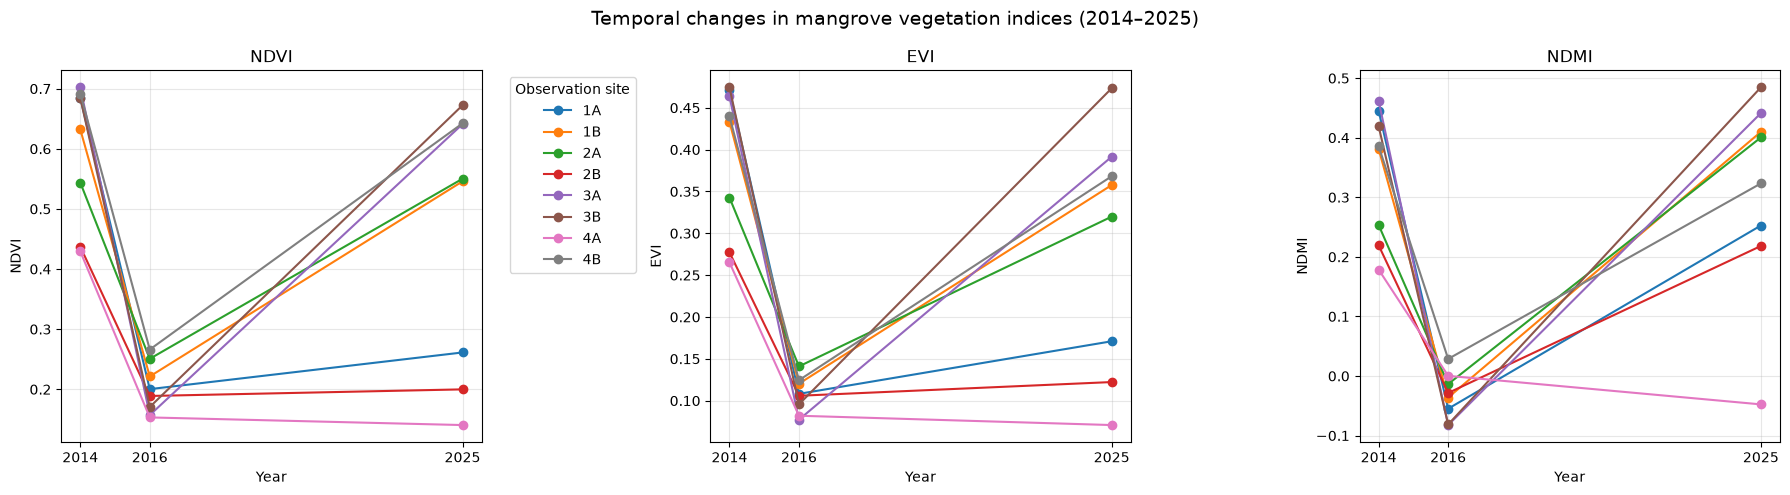

In [77]:
import matplotlib.pyplot as plt

indices = ["NDVI", "EVI", "NDMI"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True
)

for ax, index in zip(axes, indices):

    for site in environmental_wide["Site_Code"].unique():

        site_data_plot = environmental_wide[
            environmental_wide["Site_Code"] == site
        ].sort_values("Year")

        ax.plot(
            site_data_plot["Year"],
            site_data_plot[index],
            marker="o",
            linewidth=1.5,
            label=site
        )

    ax.set_title(index)
    ax.set_xlabel("Year")
    ax.set_ylabel(index)
    ax.set_xticks([2014, 2016, 2025])
    ax.grid(alpha=0.3)

axes[0].legend(
    title="Observation site",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.suptitle(
    "Temporal changes in mangrove vegetation indices (2014–2025)",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 10.5 Scatterplots: vegetation indices versus climate variables
### 10.5.1 Wet-season rainfall

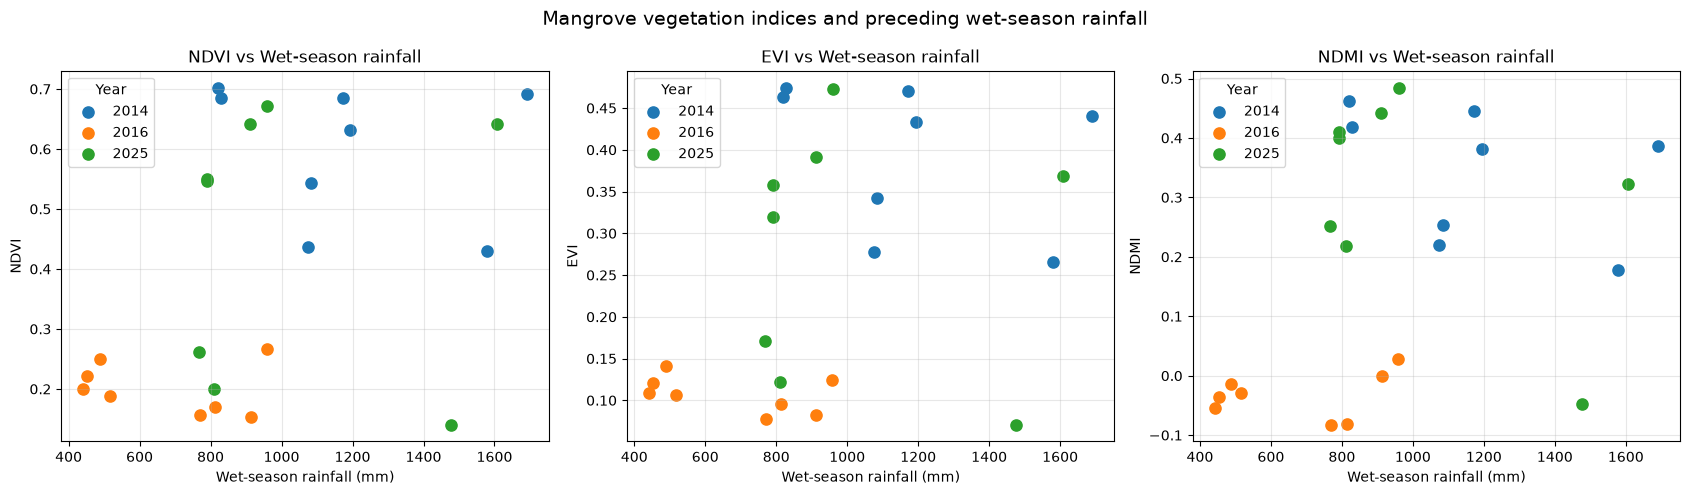

In [78]:
import matplotlib.pyplot as plt

vegetation_indices = ["NDVI", "EVI", "NDMI"]

rainfall_variable = "Total_Rainfall_mm_Wet_Season"

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, index in zip(axes, vegetation_indices):

    for year in sorted(environmental_wide["Year"].unique()):

        subset = environmental_wide[
            environmental_wide["Year"] == year
        ]

        ax.scatter(
            subset[rainfall_variable],
            subset[index],
            label=str(year),
            s=65
        )

    ax.set_title(f"{index} vs Wet-season rainfall")
    ax.set_xlabel("Wet-season rainfall (mm)")
    ax.set_ylabel(index)
    ax.grid(alpha=0.3)
    ax.legend(title="Year")

plt.suptitle(
    "Mangrove vegetation indices and preceding wet-season rainfall",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 10.5.2 Observation-season rainfall

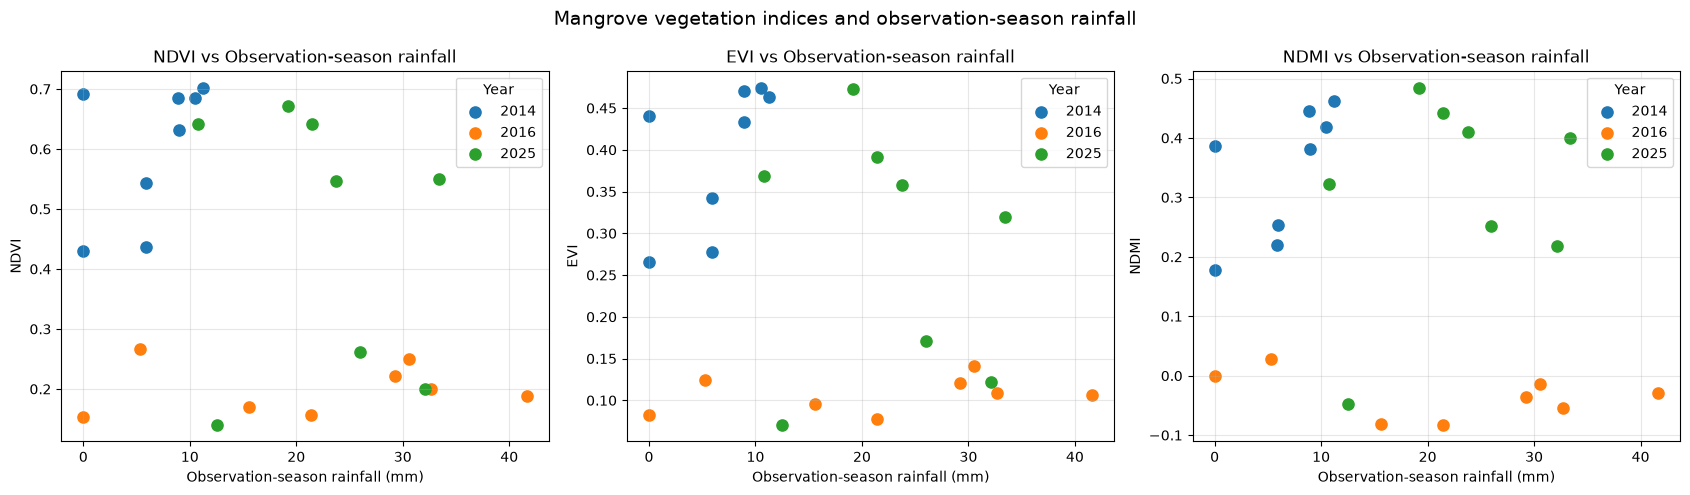

In [79]:
rainfall_variable = "Total_Rainfall_mm_Observation_Season"

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, index in zip(axes, vegetation_indices):

    for year in sorted(environmental_wide["Year"].unique()):

        subset = environmental_wide[
            environmental_wide["Year"] == year
        ]

        ax.scatter(
            subset[rainfall_variable],
            subset[index],
            label=str(year),
            s=65
        )

    ax.set_title(f"{index} vs Observation-season rainfall")
    ax.set_xlabel("Observation-season rainfall (mm)")
    ax.set_ylabel(index)
    ax.grid(alpha=0.3)
    ax.legend(title="Year")

plt.suptitle(
    "Mangrove vegetation indices and observation-season rainfall",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 10.5.3 Wet-season temperature

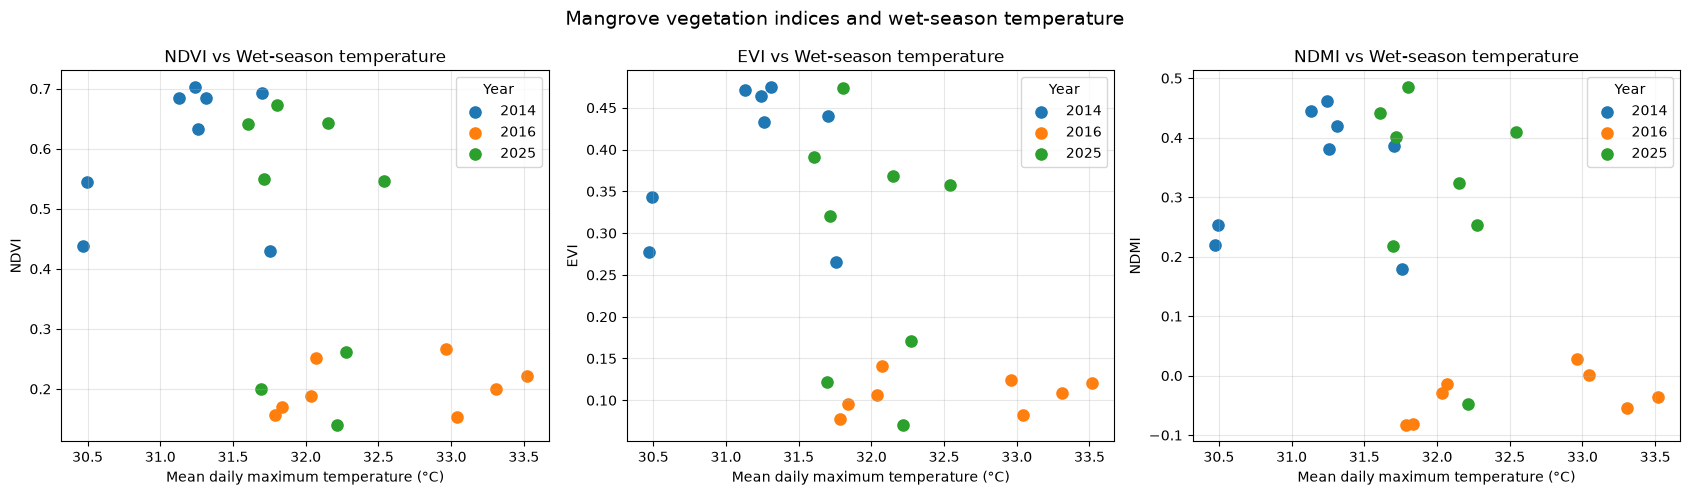

In [80]:
temperature_variable = (
    "Mean_Daily_Max_Temperature_C_Wet_Season"
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, index in zip(axes, vegetation_indices):

    for year in sorted(environmental_wide["Year"].unique()):

        subset = environmental_wide[
            environmental_wide["Year"] == year
        ]

        ax.scatter(
            subset[temperature_variable],
            subset[index],
            label=str(year),
            s=65
        )

    ax.set_title(f"{index} vs Wet-season temperature")
    ax.set_xlabel("Mean daily maximum temperature (°C)")
    ax.set_ylabel(index)
    ax.grid(alpha=0.3)
    ax.legend(title="Year")

plt.suptitle(
    "Mangrove vegetation indices and wet-season temperature",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 10.5.4 Observation-season temperature

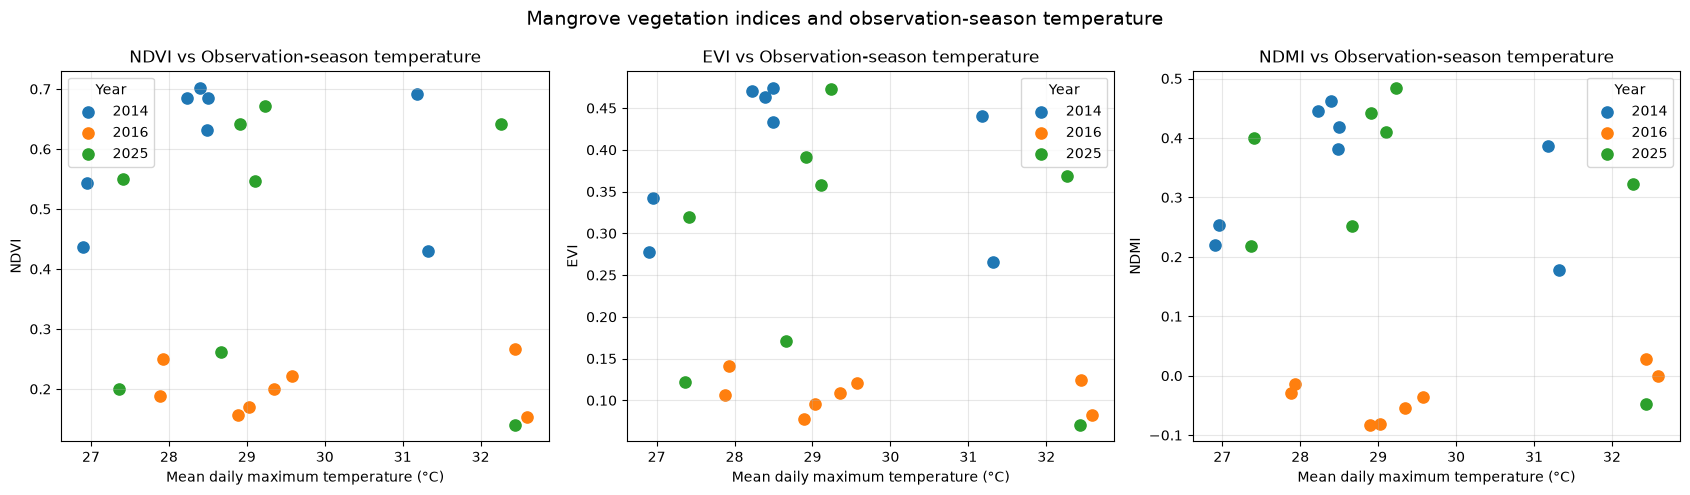

In [81]:
temperature_variable = (
    "Mean_Daily_Max_Temperature_C_Observation_Season"
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, index in zip(axes, vegetation_indices):

    for year in sorted(environmental_wide["Year"].unique()):

        subset = environmental_wide[
            environmental_wide["Year"] == year
        ]

        ax.scatter(
            subset[temperature_variable],
            subset[index],
            label=str(year),
            s=65
        )

    ax.set_title(f"{index} vs Observation-season temperature")
    ax.set_xlabel("Mean daily maximum temperature (°C)")
    ax.set_ylabel(index)
    ax.grid(alpha=0.3)
    ax.legend(title="Year")

plt.suptitle(
    "Mangrove vegetation indices and observation-season temperature",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 10.6 Pearson and Spearman correlation analysis

In [82]:
from scipy.stats import pearsonr, spearmanr

# Variables
vegetation_indices = ["NDVI", "EVI", "NDMI"]

climate_variables = [
    "Total_Rainfall_mm_Wet_Season",
    "Total_Rainfall_mm_Observation_Season",
    "Mean_Temperature_C_Wet_Season",
    "Mean_Temperature_C_Observation_Season",
    "Mean_Daily_Max_Temperature_C_Wet_Season",
    "Mean_Daily_Max_Temperature_C_Observation_Season"
]

# Calculate correlations
correlation_results = []

for vegetation in vegetation_indices:

    for climate in climate_variables:

        subset = environmental_wide[
            [vegetation, climate]
        ].dropna()

        if len(subset) >= 3:

            pearson_r, pearson_p = pearsonr(
                subset[climate],
                subset[vegetation]
            )

            spearman_r, spearman_p = spearmanr(
                subset[climate],
                subset[vegetation]
            )

            correlation_results.append({
                "Vegetation_Index": vegetation,
                "Climate_Variable": climate,
                "Sample_Size": len(subset),
                "Pearson_r": pearson_r,
                "Pearson_p": pearson_p,
                "Spearman_rho": spearman_r,
                "Spearman_p": spearman_p
            })

correlation_table = pd.DataFrame(correlation_results)

display(correlation_table.round(3))

,Vegetation_Index,Climate_Variable,Sample_Size,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,NDVI,Total_Rainfall_mm_Wet_Season,24,0.426,0.038,0.419,0.041
1,NDVI,Total_Rainfall_mm_Observation_Season,24,-0.366,0.079,-0.294,0.163
2,NDVI,Mean_Temperature_C_Wet_Season,24,-0.587,0.003,-0.580,0.003
3,NDVI,Mean_Temperature_C_Observation_Season,24,-0.377,0.070,-0.422,0.040
4,NDVI,Mean_Daily_Max_Temperature_C_Wet_Season,24,-0.547,0.006,-0.550,0.005
5,NDVI,Mean_Daily_Max_Temperature_C_Observation_Season,24,-0.165,0.442,-0.170,0.426
6,EVI,Total_Rainfall_mm_Wet_Season,24,0.394,0.056,0.407,0.048
7,EVI,Total_Rainfall_mm_Observation_Season,24,-0.360,0.084,-0.276,0.192
8,EVI,Mean_Temperature_C_Wet_Season,24,-0.589,0.002,-0.577,0.003
9,EVI,Mean_Temperature_C_Observation_Season,24,-0.430,0.036,-0.490,0.015


1. Main correlation results
A. Rainfall relationships
Vegetation index	Wet-season rainfall (Pearson r)	Observation-season rainfall (Pearson r)
NDVI	+0.426	−0.366
EVI	+0.394	−0.360
NDMI	+0.340	−0.230

Interpretation:
- Wet-season rainfall has a positive association with all three vegetation indices.
- The strongest association is with NDVI (r = 0.426, p = 0.038).
- EVI also shows a positive association, although its Pearson p-value is slightly above 0.05 (p = 0.056).
- NDMI has a weaker, statistically non-significant association (p = 0.104).
- Observation-season rainfall shows negative correlations, but none are statistically significant.
This suggests that rainfall received during the preceding wet season may be more relevant to vegetation condition than rainfall during the June–October observation period.
B. Temperature relationships
This is the most consistent finding in your results.
Vegetation index	Wet-season mean temperature	Wet-season mean daily maximum temperature
NDVI	−0.587	−0.547
EVI	−0.589	−0.568
NDMI	−0.475	−0.524

All six Pearson correlations are negative, with p-values below 0.05.

Interpretation:
- Higher wet-season temperatures are associated with lower NDVI, EVI and NDMI.
- The strongest relationship is between wet-season mean temperature and EVI (r = −0.589).
- NDVI also shows a relatively strong negative relationship (r = −0.587).
- NDMI shows a negative relationship with both mean and maximum temperature, suggesting a possible association between warmer conditions and reduced vegetation water content.
Observation-season temperature relationships are generally weaker, although some correlations with EVI and NDMI remain negative and statistically significant.

2. Overall interpretation
Across the 24 site-year observations, higher wet-season temperatures are associated with lower mangrove vegetation indices, whereas higher wet-season rainfall is generally associated with higher vegetation indices.

3. An important statistical limitation
The relationships suggest that antecedent climatic conditions may be important when examining mangrove vegetation condition.

The dataset combines three very different observation years:
- 2014: generally higher vegetation indices.
- 2016: substantially lower vegetation indices.
- 2025: mixed vegetation condition, with evidence of recovery at some sites.
Consequently, the correlations may be strongly influenced by differences between years rather than by relationships between climate and vegetation within individual years.

For example, if 2016 had warmer wet-season conditions and lower NDVI across most sites, this alone could produce a strong negative correlation.

We need to investigate this before making stronger conclusions.

## 10.7 Examine whether correlations are driven by differences between years

In [83]:
from scipy.stats import pearsonr, spearmanr

vegetation_indices = ["NDVI", "EVI", "NDMI"]

climate_variables = [
    "Total_Rainfall_mm_Wet_Season",
    "Mean_Temperature_C_Wet_Season",
    "Mean_Daily_Max_Temperature_C_Wet_Season"
]

yearly_correlations = []

for year in sorted(environmental_wide["Year"].unique()):

    year_data = environmental_wide[
        environmental_wide["Year"] == year
    ]

    for vegetation in vegetation_indices:

        for climate in climate_variables:

            subset = year_data[
                [vegetation, climate]
            ].dropna()

            if len(subset) >= 3:

                r, p = pearsonr(
                    subset[climate],
                    subset[vegetation]
                )

                yearly_correlations.append({
                    "Year": year,
                    "Vegetation_Index": vegetation,
                    "Climate_Variable": climate,
                    "Sample_Size": len(subset),
                    "Pearson_r": r,
                    "Pearson_p": p
                })

yearly_correlation_table = pd.DataFrame(
    yearly_correlations
)

display(
    yearly_correlation_table.round(3)
)

,Year,Vegetation_Index,Climate_Variable,Sample_Size,Pearson_r,Pearson_p
0,2014,NDVI,Total_Rainfall_mm_Wet_Season,8,-0.257,0.538
1,2014,NDVI,Mean_Temperature_C_Wet_Season,8,0.267,0.523
2,2014,NDVI,Mean_Daily_Max_Temperature_C_Wet_Season,8,0.309,0.457
3,2014,EVI,Total_Rainfall_mm_Wet_Season,8,-0.332,0.421
4,2014,EVI,Mean_Temperature_C_Wet_Season,8,0.332,0.422
5,2014,EVI,Mean_Daily_Max_Temperature_C_Wet_Season,8,0.279,0.504
6,2014,NDMI,Total_Rainfall_mm_Wet_Season,8,-0.381,0.352
7,2014,NDMI,Mean_Temperature_C_Wet_Season,8,0.377,0.357
8,2014,NDMI,Mean_Daily_Max_Temperature_C_Wet_Season,8,0.250,0.551
9,2016,NDVI,Total_Rainfall_mm_Wet_Season,8,-0.205,0.627


1. Interpretation of the yearly correlations
A. Temperature relationships
Consider the correlations between wet-season mean temperature and NDVI:
Year	Pearson r	p-value	Interpretation
2014	+0.267	0.523	Weak positive
2016	+0.316	0.445	Weak positive
2025	−0.076	0.858	Almost no relationship

The same general pattern occurs for EVI and NDMI: the negative temperature relationships observed in the pooled dataset are not consistently present within individual years.

This suggests that the pooled negative correlations (e.g. NDVI r = −0.587) are substantially influenced by differences between years.

In other words, the relationship may reflect the fact that 2016 had different climatic conditions and substantially lower vegetation indices than 2014, rather than a consistent relationship between temperature and vegetation across sites.
B. Rainfall relationships
The wet-season rainfall correlations are also inconsistent:
- 2014: mostly negative correlations.
- 2016: mixed correlations.
- 2025: generally weak correlations, except NDMI (r = −0.474).
There is therefore no consistent evidence that sites receiving more wet-season rainfall had higher vegetation indices within each individual year.
C. Statistical significance
None of the yearly correlations are statistically significant at the 0.05 level.

However, each analysis has only eight observations. This means statistical power is limited, and the absence of statistical significance does not establish that there is no relationship.
2. What can we conclude so far?
I would distinguish two findings:
1. Between-year association: The pooled dataset shows that years with higher wet-season temperatures tend to have lower vegetation indices.
2. Within-year association: The yearly analysis does not demonstrate a consistent relationship between differences in temperature or rainfall among sites and their vegetation condition.
This distinction is important. We should avoid claiming that higher temperatures directly caused mangrove deterioration based on the pooled correlations.

## 10.8 Examine differences in climate and vegetation between years
examining annual averages.

This will help us determine whether the pooled correlations are primarily associated with differences between 2014, 2016 and 2025.

### 10.8.1 Calculate annual averages

In [84]:
# Variables to summarise
summary_variables = [
    "NDVI",
    "EVI",
    "NDMI",
    "Total_Rainfall_mm_Wet_Season",
    "Mean_Temperature_C_Wet_Season",
    "Mean_Daily_Max_Temperature_C_Wet_Season"
]

# Calculate mean values by year
annual_summary = (
    environmental_wide
    .groupby("Year")[summary_variables]
    .mean()
    .reset_index()
)

display(annual_summary.round(3))

,Year,NDVI,EVI,NDMI,Total_Rainfall_mm_Wet_Season,Mean_Temperature_C_Wet_Season,Mean_Daily_Max_Temperature_C_Wet_Season
0,2014,0.601,0.396,0.343,1180.007,28.251,31.171
1,2016,0.201,0.107,-0.033,669.243,29.408,32.571
2,2025,0.457,0.284,0.310,1014.426,29.049,32.000


### 10.8.2 Plot annual vegetation and climate patterns

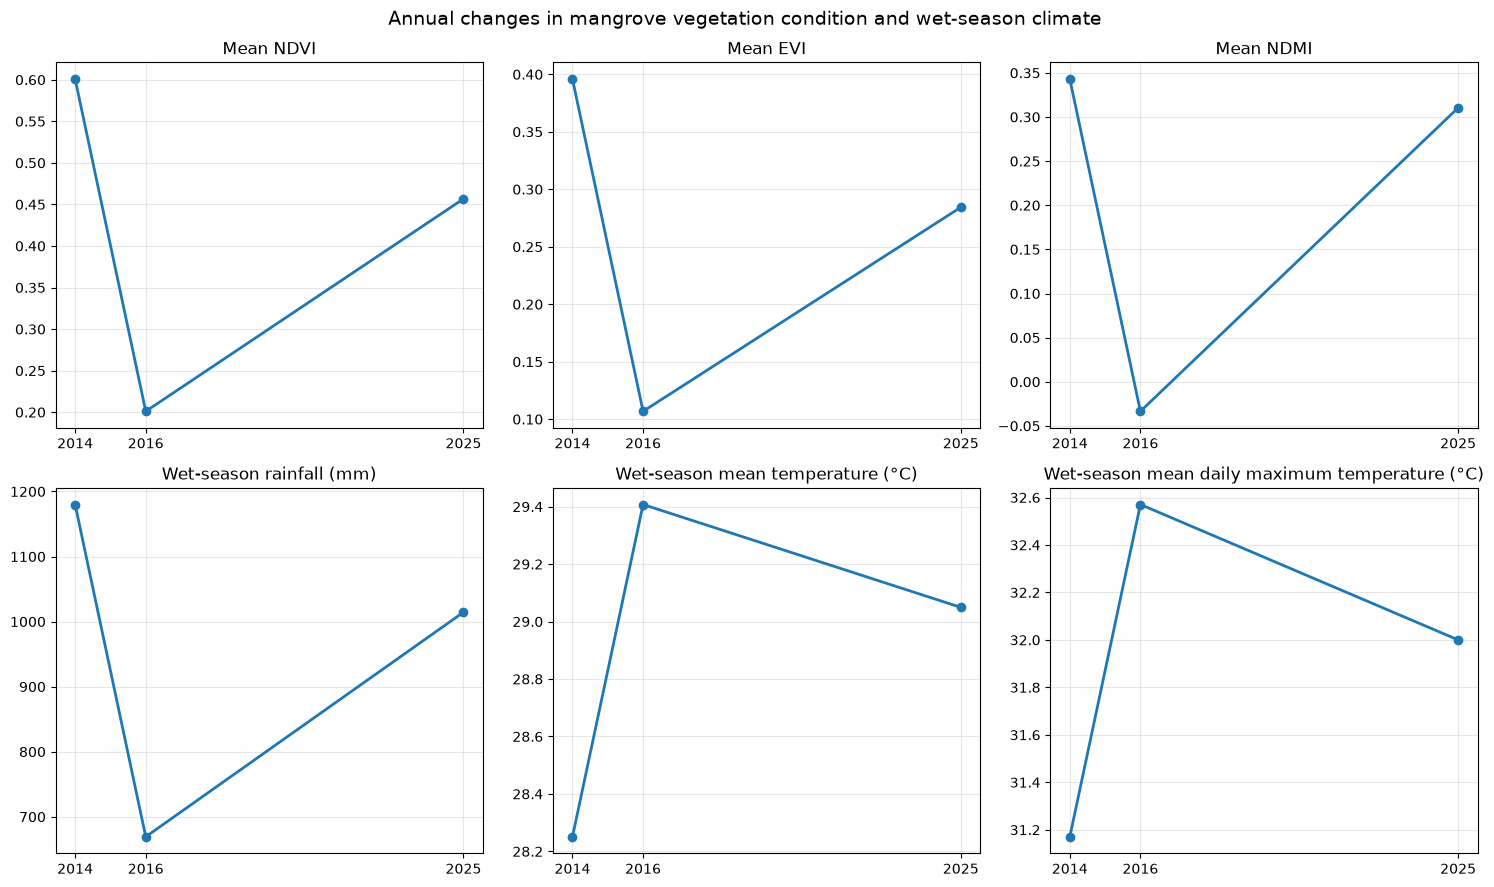

In [85]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

variables = [
    ("NDVI", "Mean NDVI"),
    ("EVI", "Mean EVI"),
    ("NDMI", "Mean NDMI"),
    ("Total_Rainfall_mm_Wet_Season", "Wet-season rainfall (mm)"),
    ("Mean_Temperature_C_Wet_Season", "Wet-season mean temperature (°C)"),
    ("Mean_Daily_Max_Temperature_C_Wet_Season",
     "Wet-season mean daily maximum temperature (°C)")
]

for ax, (variable, label) in zip(axes.flat, variables):

    ax.plot(
        annual_summary["Year"],
        annual_summary[variable],
        marker="o",
        linewidth=2
    )

    ax.set_title(label)
    ax.set_xticks([2014, 2016, 2025])
    ax.grid(alpha=0.3)

plt.suptitle(
    "Annual changes in mangrove vegetation condition and wet-season climate",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 10.8.3 Calculate percentage changes in vegetation indices

In [86]:
vegetation_indices = ["NDVI", "EVI", "NDMI"]

annual_vegetation_change = annual_summary[
    ["Year"] + vegetation_indices
].set_index("Year")

percentage_changes = pd.DataFrame({
    "2016_vs_2014_%": (
        (annual_vegetation_change.loc[2016] -
         annual_vegetation_change.loc[2014]) /
        annual_vegetation_change.loc[2014] * 100
    ),
    "2025_vs_2014_%": (
        (annual_vegetation_change.loc[2025] -
         annual_vegetation_change.loc[2014]) /
        annual_vegetation_change.loc[2014] * 100
    ),
    "2025_vs_2016_%": (
        (annual_vegetation_change.loc[2025] -
         annual_vegetation_change.loc[2016]) /
        annual_vegetation_change.loc[2016] * 100
    )
})

display(percentage_changes.round(2))

,2016_vs_2014_%,2025_vs_2014_%,2025_vs_2016_%
NDVI,-66.54,-23.99,127.15
EVI,-73.01,-28.18,166.15
NDMI,-109.76,-9.51,-1026.81


**Important interpretation**

The results indicate a strong temporal association between the 2016 climatic conditions and reduced mangrove vegetation indices, followed by an improvement in 2025.

However, the three observation years cannot establish causation or demonstrate that all sites recovered at the same rate.

## 10.9 patial differences in mangrove dieback and recovery
Now let's investigate whether the four locations experienced similar changes or whether some locations were more affected than others.

We will compare:
- Limmen: Sites 1A and 1B
- Mule: Sites 2A and 2B
- Karumba: Sites 3A and 3B
- Mitchell: Sites 4A and 4B
We will initially calculate the mean for the two sites within each location, while retaining the individual site results for further investigation.

### 10.9.1 Calculate vegetation indices by location and year

In [87]:
# Vegetation indices
vegetation_indices = ["NDVI", "EVI", "NDMI"]

# Calculate mean vegetation indices for each location and year
location_summary = (
    environmental_wide
    .groupby(["Location", "Year"])[vegetation_indices]
    .agg(["mean", "std", "count"])
)

# Flatten column names
location_summary.columns = [
    f"{variable}_{statistic}"
    for variable, statistic in location_summary.columns
]

location_summary = location_summary.reset_index()

display(location_summary.round(3))

,Location,Year,NDVI_mean,NDVI_std,NDVI_count,EVI_mean,EVI_std,EVI_count,NDMI_mean,NDMI_std,NDMI_count
0,Karumba,2014,0.693,0.012,2,0.469,0.008,2,0.440,0.030,2
1,Karumba,2016,0.164,0.010,2,0.086,0.013,2,-0.082,0.001,2
2,Karumba,2025,0.657,0.022,2,0.432,0.058,2,0.463,0.031,2
3,Limmen,2014,0.659,0.037,2,0.452,0.027,2,0.413,0.045,2
4,Limmen,2016,0.211,0.015,2,0.114,0.009,2,-0.046,0.013,2
5,Limmen,2025,0.404,0.201,2,0.264,0.132,2,0.331,0.111,2
6,Mitchell,2014,0.561,0.186,2,0.353,0.124,2,0.282,0.146,2
7,Mitchell,2016,0.210,0.080,2,0.103,0.030,2,0.014,0.020,2
8,Mitchell,2025,0.391,0.355,2,0.220,0.210,2,0.138,0.262,2
9,Mule,2014,0.491,0.075,2,0.310,0.046,2,0.236,0.024,2


### 10.9.2 Plot vegetation changes across the four locations

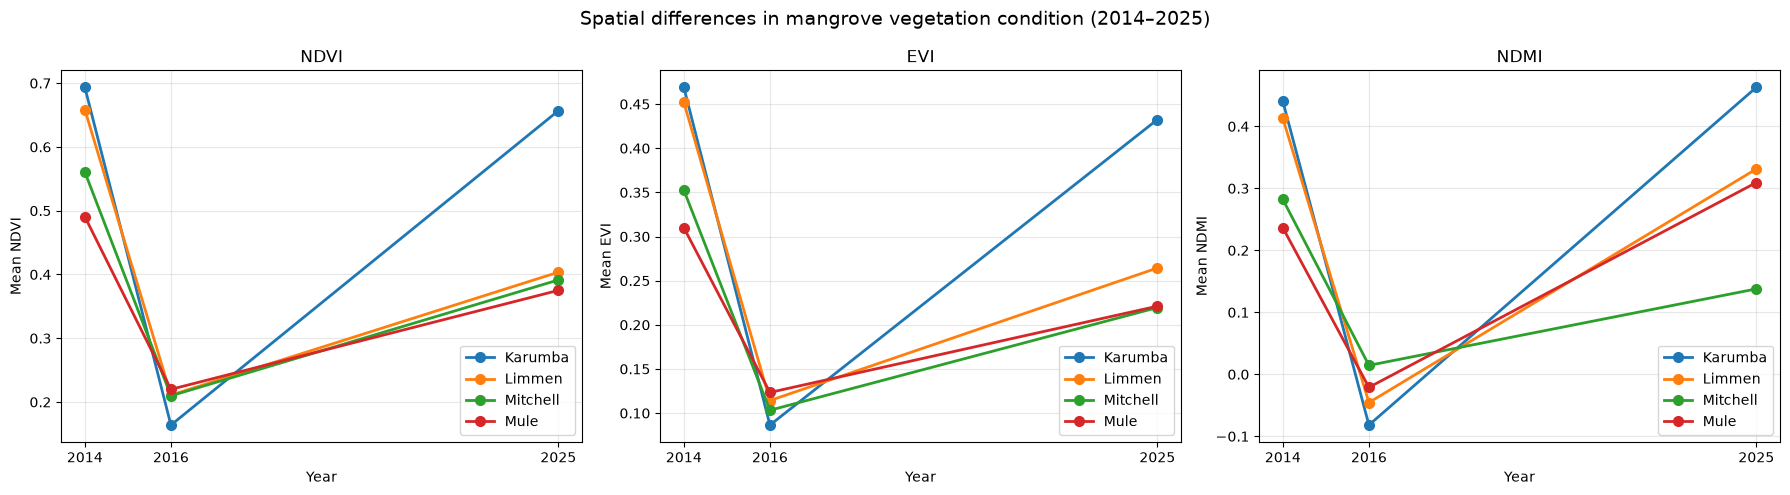

In [88]:
import matplotlib.pyplot as plt

vegetation_indices = ["NDVI", "EVI", "NDMI"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True
)

for ax, index in zip(axes, vegetation_indices):

    for location in location_summary["Location"].unique():

        subset = location_summary[
            location_summary["Location"] == location
        ].sort_values("Year")

        ax.plot(
            subset["Year"],
            subset[f"{index}_mean"],
            marker="o",
            linewidth=2,
            markersize=7,
            label=location
        )

    ax.set_title(index)
    ax.set_xlabel("Year")
    ax.set_ylabel(f"Mean {index}")
    ax.set_xticks([2014, 2016, 2025])
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Spatial differences in mangrove vegetation condition (2014–2025)",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 10.9.3 Calculate the magnitude of dieback and recovery by location

In [89]:
# Extract mean vegetation indices by location and year
location_pivot = location_summary.pivot(
    index="Location",
    columns="Year",
    values=["NDVI_mean", "EVI_mean", "NDMI_mean"]
)

# Calculate absolute changes
spatial_changes = pd.DataFrame(index=location_pivot.index)

for index in vegetation_indices:

    spatial_changes[f"{index}_Change_2014_2016"] = (
        location_pivot[(f"{index}_mean", 2016)]
        - location_pivot[(f"{index}_mean", 2014)]
    )

    spatial_changes[f"{index}_Change_2016_2025"] = (
        location_pivot[(f"{index}_mean", 2025)]
        - location_pivot[(f"{index}_mean", 2016)]
    )

    spatial_changes[f"{index}_Change_2014_2025"] = (
        location_pivot[(f"{index}_mean", 2025)]
        - location_pivot[(f"{index}_mean", 2014)]
    )

spatial_changes = spatial_changes.reset_index()

display(spatial_changes.round(3))

,Location,NDVI_Change_2014_2016,NDVI_Change_2016_2025,NDVI_Change_2014_2025,EVI_Change_2014_2016,EVI_Change_2016_2025,EVI_Change_2014_2025,NDMI_Change_2014_2016,NDMI_Change_2016_2025,NDMI_Change_2014_2025
0,Karumba,-0.530,0.493,-0.037,-0.383,0.346,-0.037,-0.522,0.545,0.023
1,Limmen,-0.448,0.193,-0.255,-0.338,0.150,-0.188,-0.459,0.377,-0.082
2,Mitchell,-0.351,0.182,-0.169,-0.249,0.116,-0.133,-0.268,0.123,-0.144
3,Mule,-0.271,0.155,-0.116,-0.187,0.098,-0.089,-0.257,0.330,0.073


## 10.10 Examine differences between individual observation sites
### 10.10.1 Calculate vegetation changes by individual site

In [90]:
# Vegetation indices
vegetation_indices = ["NDVI", "EVI", "NDMI"]

# Reshape the dataset to compare years
site_pivot = environmental_wide.pivot(
    index=["Location", "Site_Code"],
    columns="Year",
    values=vegetation_indices
)

# Calculate changes for individual sites
site_changes = pd.DataFrame(
    index=site_pivot.index
)

for index in vegetation_indices:

    site_changes[f"{index}_2014_2016"] = (
        site_pivot[(index, 2016)]
        - site_pivot[(index, 2014)]
    )

    site_changes[f"{index}_2016_2025"] = (
        site_pivot[(index, 2025)]
        - site_pivot[(index, 2016)]
    )

    site_changes[f"{index}_2014_2025"] = (
        site_pivot[(index, 2025)]
        - site_pivot[(index, 2014)]
    )

site_changes = site_changes.reset_index()

display(site_changes.round(3))

,Location,Site_Code,NDVI_2014_2016,NDVI_2016_2025,NDVI_2014_2025,EVI_2014_2016,EVI_2016_2025,EVI_2014_2025,NDMI_2014_2016,NDMI_2016_2025,NDMI_2014_2025
0,Karumba,3A,-0.545,0.484,-0.061,-0.386,0.314,-0.072,-0.544,0.524,-0.020
1,Karumba,3B,-0.514,0.502,-0.012,-0.379,0.378,-0.001,-0.500,0.566,0.066
2,Limmen,1A,-0.484,0.061,-0.423,-0.363,0.063,-0.300,-0.500,0.308,-0.192
3,Limmen,1B,-0.411,0.324,-0.087,-0.313,0.237,-0.076,-0.417,0.446,0.029
4,Mitchell,4A,-0.276,-0.013,-0.289,-0.183,-0.011,-0.194,-0.178,-0.048,-0.226
5,Mitchell,4B,-0.426,0.376,-0.050,-0.315,0.244,-0.072,-0.357,0.295,-0.062
6,Mule,2A,-0.293,0.299,0.006,-0.202,0.179,-0.023,-0.267,0.414,0.147
7,Mule,2B,-0.248,0.011,-0.237,-0.171,0.016,-0.155,-0.248,0.247,-0.001


### 10.10.2 Visualise individual site responses

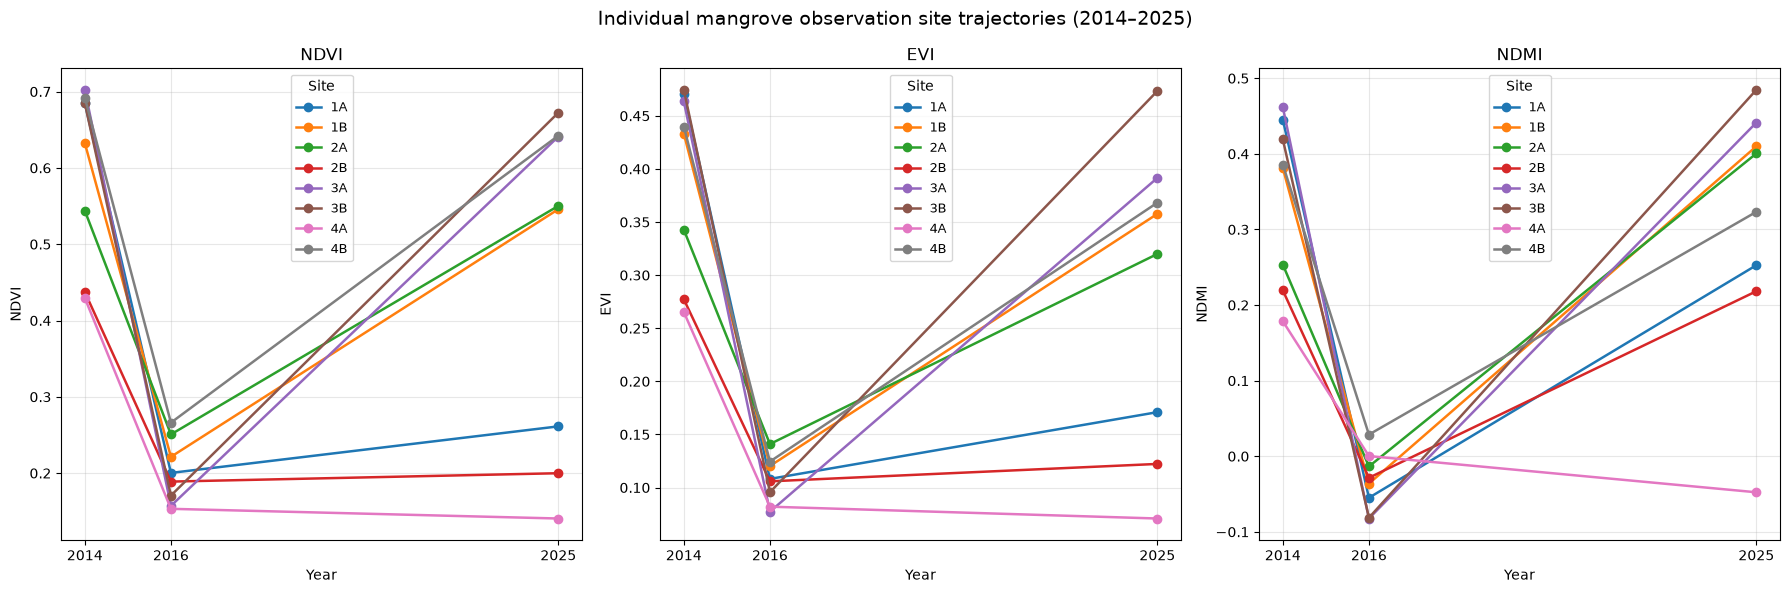

In [91]:
import matplotlib.pyplot as plt

vegetation_indices = ["NDVI", "EVI", "NDMI"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    sharex=True
)

for ax, index in zip(axes, vegetation_indices):

    for site in environmental_wide["Site_Code"].unique():

        subset = environmental_wide[
            environmental_wide["Site_Code"] == site
        ].sort_values("Year")

        ax.plot(
            subset["Year"],
            subset[index],
            marker="o",
            linewidth=1.8,
            markersize=6,
            label=site
        )

    ax.set_title(index)
    ax.set_xlabel("Year")
    ax.set_ylabel(index)
    ax.set_xticks([2014, 2016, 2025])
    ax.grid(alpha=0.3)
    ax.legend(title="Site", fontsize=9)

plt.suptitle(
    "Individual mangrove observation site trajectories (2014–2025)",
    fontsize=14
)

plt.tight_layout()
plt.show()